In [1]:
# Load the development file (train + validation rows ONLY)
# Runs locally (no Colab). The test rows live in a separate file that this notebook does not open
# until the single final evaluation (decision R9).
import os
import numpy as np
import pandas as pd

DERIVED = os.path.join("data", "derived")
OUTPUTS = "outputs"
os.makedirs(OUTPUTS, exist_ok=True)

data = pd.read_csv(os.path.join(DERIVED, "dev_set_train_and_validation.csv"))
print(data.shape, data["split"].value_counts().to_dict())
assert set(data["split"]) == {"train", "val"}, "dev file must contain no test rows"

(347170, 37) {'train': 303773, 'val': 43397}


In [2]:
# Settings used by every model

# Import statements
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score, roc_auc_score, confusion_matrix
import re, time

SEED = 75   # approved seed (R3); used for every random step
CUTOFF = 0.50   # single fixed decision cutoff for every model and subgroup (R4, R5)

age_sex = ["_AGEG5YR", "SEXVAR"]
socio = ["_RACEGR3", "_EDUCAG", "_INCOMG1", "_URBSTAT"]
other = ["BMI", "_SMOKER3", "EXERANY2", "ALC_DAYS30", "_HLTHPL2", "PERSDOC3",
           "MEDCOST1", "CHECKUP1", "GENHLTH", "PHYSHLTH", "MENTHLTH"]
sdoh = ["SDLONELY", "SDHEMPLY", "FOODSTMP", "SDHFOOD1", "SDHBILLS", "SDHUTILS", "SDHTRNSP"]

MODELS = {"M0": age_sex,
          "M1": age_sex + socio,
          "M2": age_sex + socio + other,
          "M3": age_sex + socio + other + sdoh}

# How each feature is treated by the pipeline
CATEGORICAL = ["_AGEG5YR", "SEXVAR", "_RACEGR3", "_INCOMG1", "_URBSTAT", "_SMOKER3", "_HLTHPL2",
               "PERSDOC3", "EXERANY2", "MEDCOST1", "SDHEMPLY", "FOODSTMP", "SDHBILLS", "SDHUTILS", "SDHTRNSP"]
NUMERIC = ["_EDUCAG", "BMI", "ALC_DAYS30", "CHECKUP1", "GENHLTH", "PHYSHLTH", "MENTHLTH",
               "SDLONELY", "SDHFOOD1"]
GROUPS = ["grp_age", "grp_sex", "grp_race", "grp_income", "grp_urban"]

assert set(MODELS["M3"]) == set(CATEGORICAL) | set(NUMERIC) # every feature has a treatment

In [3]:
# Reusable functions

SCORES_DIR = os.path.join(OUTPUTS, "scores")    # cached predicted scores (so a restart does not force retraining)
os.makedirs(SCORES_DIR, exist_ok=True)

# make_pipeline
# - builds an untrained model from a list of feature names
# - sorts the features by treatment, sets up preprocessing, attaches the model
def make_pipeline(features, kind="logreg"):
    # Preprocessing + model in one object; everything is learned from the rows it is fit on (training rows only)
    cat = [f for f in features if f in CATEGORICAL]
    num = [f for f in features if f in NUMERIC]
    num_steps = [("impute", SimpleImputer(strategy="median", add_indicator=True))]
    if kind == "logreg":
        num_steps.append(("scale", StandardScaler()))
    parts = []
    if cat:
        parts.append(("cat", OneHotEncoder(handle_unknown="ignore"), cat))
    if num:
        parts.append(("num", Pipeline(num_steps), num))
    if kind == "logreg":
        clf = LogisticRegression(max_iter=1000)
    else:  # random forest
        clf = RandomForestClassifier(n_estimators=300, min_samples_leaf=50, n_jobs=-1, random_state=SEED)
    return Pipeline([("prep", ColumnTransformer(parts)), ("clf", clf)])

def get_part(df, split, sdoh_only=False):
    # Rows of one split (train/val), optionally only respondents asked the SDOH module
    part = df[df["split"] == split]
    return part[part["has_sdoh"]] if sdoh_only else part

def score(y, p, threshold=CUTOFF):
    # All the metrics we report, for any set of respondents, at a given cutoff.
    # If nobody is flagged, precision and F1 are UNDEFINED (NaN, printed as "undefined"), not zero,
    # and the model is still reported.
    y, p = np.asarray(y), np.asarray(p)
    pred = (p >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    flagged = tp + fp
    rec  = tp / (tp + fn) if (tp + fn) else np.nan
    prec = tp / flagged if flagged else np.nan
    f1   = 2 * tp / (2 * tp + fp + fn) if flagged else np.nan   # same as the harmonic mean of precision and recall
    two = len(np.unique(y)) == 2      # AUCs need both outcomes present
    return {"n": len(y), "positives": int(y.sum()), "prevalence": y.mean(),
            "PR-AUC": average_precision_score(y, p) if two else np.nan,
            "ROC-AUC": roc_auc_score(y, p) if two else np.nan,
            "recall": rec, "precision": prec, "F1": f1,
            "false_pos_rate": fp / (fp + tn) if (fp + tn) else np.nan,
            "accuracy": (tp + tn) / len(y),
            "flagged_%": 100 * flagged / len(y),
            "caught": int(tp), "missed": int(fn), "false_alarms": int(fp), "cleared": int(tn)}

def slug(name):
    return re.sub(r"[^A-Za-z0-9]+", "_", name).strip("_")

def run_model(name, features, kind="logreg", sdoh_only=False, tag="step4", params=None):
    # Train on the TRAINING rows, score the VALIDATION rows at the fixed cutoff, cache the scores to disk.
    # (The test file is not opened here; the final evaluation is a separate step.)
    train = get_part(data, "train", sdoh_only)
    val   = get_part(data, "val", sdoh_only)
    t0 = time.time()
    pipe = make_pipeline(features, kind)
    if params:                                   # chosen settings from tuning, e.g. {"C": 1}
        pipe.set_params(**{f"clf__{k}": v for k, v in params.items()})
    pipe.fit(train[features], train["target"])
    p = pipe.predict_proba(val[features])[:, 1]
    secs = time.time() - t0
    cache = val[["_STATE", "SEQNO", "split", "target"]].assign(model=name, p=p)
    cache.to_csv(os.path.join(SCORES_DIR, f"{tag}_val_{slug(name)}.csv"), index=False)
    row = {"model": name, "kind": kind, "set": "val", "features": len(features), "cutoff": CUTOFF,
           "settings": str(params or "defaults"),
           **score(val["target"], p), "fit_seconds": round(secs)}
    return {"pipe": pipe, "part": val, "p": p, "threshold": CUTOFF, "row": row}

def load_scores(name, tag="step4"):
    # Read cached validation scores instead of retraining
    return pd.read_csv(os.path.join(SCORES_DIR, f"{tag}_val_{slug(name)}.csv"))

def by_group(res, groups=GROUPS):
    # Same metrics inside every subgroup, using the SAME cutoff for everyone (R5)
    tmp = res["part"].assign(p=res["p"])
    rows = []
    for g in groups:
        for level, sub in tmp.groupby(g, observed=True):
            rows.append({"model": res["row"]["model"], "grouping": g, "group": level,
                         **score(sub["target"], sub["p"], res["threshold"])})
    return pd.DataFrame(rows)

def fmt(x):
    return "undefined" if pd.isna(x) else f"{x:.3f}"

def show(res):
    r = res["row"]
    print(f"{r['model']} on {r['set']} | cutoff {r['cutoff']:.2f} | fit {r['fit_seconds']}s")
    print(f"PR-AUC {fmt(r['PR-AUC'])} | ROC-AUC {fmt(r['ROC-AUC'])}")
    print(f"Recall {fmt(r['recall'])} | Precision {fmt(r['precision'])} | F1 {fmt(r['F1'])} | "
          f"FPR {fmt(r['false_pos_rate'])} | accuracy {fmt(r['accuracy'])} | flagged {r['flagged_%']:.2f}%")
    print(f"Caught {r['caught']} | Missed {r['missed']} | False alarms {r['false_alarms']} | Cleared {r['cleared']}\n")

all_rows = []     # running results table; cleared before each batch so reruns do not duplicate rows

def record(res, out="step4_validation_results.csv"):
    # Add a model's overall results to the running table and save it to outputs/
    all_rows.append(res["row"])
    table = pd.DataFrame(all_rows)
    table.to_csv(os.path.join(OUTPUTS, out), index=False)
    return table

# Notebook guide (read this first)
This notebook trains and evaluates every model. It runs top to bottom from a clean kernel after `01_Data_Preprocessing.ipynb`.
Decision IDs in brackets (R4, T2c, FIG1b, ...) are labels from our internal decision log (not in this repository); the choices are explained in our report.
Comments that cite `INSTRUCTIONS.md` refer to our internal planning notes, which are also not part of this repository.

**Where each report item comes from** (all files are in `outputs/`; `outputs/README.md` lists every file):

| Report item | Cell (section) | File |
|---|---|---|
| Table 1: test metrics, M0–M2, cutoffs 0.15 and 0.50 | Step 10b | `table1_test_metrics_M0_M2.csv` |
| Table 2: test metrics, M2-module vs M3 | Step 10b | `table2_test_metrics_M2_vs_M3_module.csv` |
| Figure 1: confusion matrices, M0–M2 logistic regression | Step 10b | `fig_main1_confusion_matrices_logistic_test.png` |
| Figure 2: subgroup recall and precision, M2 logistic regression, 0.15 | Step 10b | `fig_main2_subgroup_recall_precision_M2_logistic_test.png` |
| Figure 3: confusion matrices, M2-module vs M3, 0.15 | Step 10b | `fig_main3_confusion_M2_vs_M3_logistic_015_test.png` |
| Leakage checks | this section, and notebook 01 | `step3_leakage_checks_*.csv` |
| Tuning results and chosen settings | Steps 5, 5b, 8a, 8b | `step5_*`, `step8_tuning_*`, `step8_chosen_settings_*` |
| Appendix candidates (threshold table, both-cutoff subgroup figure, PR curves, calibration, permutation importance, within-age-band check, 8-panel M2 vs M3 matrices) | Steps 6, 7, 8, 10a, 10b | see `outputs/README.md` |

**Sections marked "development only" or "superseded"** made figures that were later replaced by the report's main figures (the cutoff and figure decisions R7b and FIG1–FIG4 came after them). They are kept, not deleted, because they ran at the time of the single test evaluation and they record what was done at the time.

---

## Leakage checks 3 to 6 (step 3; rerun before the final test evaluation)
Checks 1 and 2 (disjoint identifiers, split sizes and positive rates) run in `01_Data_Preprocessing.ipynb`, where all three parts exist.
These four use only the development file.

In [4]:
# Leakage checks 3 to 6 (INSTRUCTIONS.md section 6)
import glob, json
leak_results = []
def check(name, ok, detail=""):
    leak_results.append({"check": name, "pass": bool(ok), "detail": detail})
    print(f"{'PASS' if ok else 'FAIL'}  {name}  {detail}")

train = get_part(data, "train")
val   = get_part(data, "val")

# Check 3: no target, label, split, has_sdoh or grp_* column is used as a feature
forbidden = {"target", "DIABETE4", "split", "has_sdoh"}
for m, feats in MODELS.items():
    bad = [f for f in feats if f in forbidden or f.startswith("grp_")]
    check(f"3. {m} feature list has no target/split/has_sdoh/grp_* columns", not bad, str(bad) if bad else "")

# Check 4: fitted imputation medians and scaler means come from training rows only
feats = MODELS["M3"]
prep = make_pipeline(feats, "logreg").named_steps["prep"].fit(train[feats])
num_pipe = prep.named_transformers_["num"]
num = [f for f in feats if f in NUMERIC]
fit_med  = pd.Series(num_pipe.named_steps["impute"].statistics_, index=num)
fit_mean = pd.Series(num_pipe.named_steps["scale"].mean_[:len(num)], index=num)
train_med  = train[num].median()
train_mean = train[num].fillna(train_med).mean()
all_row_stats = pd.read_csv(os.path.join(OUTPUTS, "step3_all_rows_feature_stats.csv"), index_col=0)
c4 = pd.DataFrame({"fitted_median": fit_med, "train_median": train_med, "all_rows_median": all_row_stats["median_all_rows"],
                   "fitted_mean": fit_mean, "train_mean": train_mean,
                   "all_rows_mean": all_row_stats["mean_after_median_fill_all_rows"]})
c4.to_csv(os.path.join(OUTPUTS, "step3_leakage_check4_medians_means.csv"))
print(c4.round(5))
check("4a. fitted medians equal training-row medians", np.allclose(c4["fitted_median"], c4["train_median"]))
check("4b. fitted scaler means equal training-row means", np.allclose(c4["fitted_mean"], c4["train_mean"]))
check("4c. fitted scaler means differ from all-row means", not np.allclose(c4["fitted_mean"], c4["all_rows_mean"], rtol=0, atol=1e-9),
      f"{int((~np.isclose(c4['fitted_mean'], c4['all_rows_mean'], rtol=0, atol=1e-9)).sum())} of {len(num)} differ")
n_med_diff = int((c4["fitted_median"] != c4["all_rows_median"]).sum())
print(f"note  medians differing from all-row medians: {n_med_diff} of {len(num)} "
      "(medians of whole-number survey answers are usually identical in any large sample, so equality is expected)")

# Check 5 (decision L5): a model trained on SHUFFLED training labels should score ROC-AUC near 0.5.
# Repeat over 10 shuffles (one generator seeded with SEED); pass if the MEAN validation ROC-AUC is within 0.02 of 0.5.
# Leakage would push scores ABOVE 0.5; one shuffle can land a bit off 0.5 by chance, so we average.
N_SHUFFLES, TOL = 10, 0.02
rng = np.random.default_rng(SEED)
y_train = train["target"].to_numpy()
shuffle_aucs = []
for r in range(N_SHUFFLES):
    pipe = make_pipeline(MODELS["M2"], "logreg")
    pipe.fit(train[MODELS["M2"]], rng.permutation(y_train))
    shuffle_aucs.append(roc_auc_score(val["target"], pipe.predict_proba(val[MODELS["M2"]])[:, 1]))
c5 = pd.DataFrame({"shuffle": range(1, N_SHUFFLES + 1), "val_ROC_AUC": shuffle_aucs})
c5.to_csv(os.path.join(OUTPUTS, "step3_leakage_check5_shuffles.csv"), index=False)
print(c5.round(4).to_string(index=False))
mean_auc = float(np.mean(shuffle_aucs))
check("5. M2 logistic regression on shuffled labels: MEAN validation ROC-AUC over 10 shuffles within 0.02 of 0.5",
      abs(mean_auc - 0.5) < TOL,
      f"mean = {mean_auc:.4f}, min = {min(shuffle_aucs):.4f}, max = {max(shuffle_aucs):.4f}")

# Check 6: no code path reads the test file, or a pre-split file that still contains test rows, before the final step
TEST_NAME = "TEST_SET_DO_NOT_OPEN_until_final_evaluation"
# Line by line: a hit is a line that both READS a file and names one of these data files.
DATA_NAMES = [TEST_NAME, "brfss2024_clean", "brfss2024_model", "brfss2024_slim"]
FINAL_MARK = "# STEP 7: FINAL TEST EVALUATION"   # the ONLY cell allowed to read the test file
hits, bad_hits, final_cells, fits_after_final = [], [], [], []
for nb_path in sorted(glob.glob("*.ipynb")):
    if nb_path.startswith("Final Project"):      # the untouched original notebooks are kept for reference and not run
        continue
    cells = json.load(open(nb_path))["cells"]
    for k, cell in enumerate(cells):
        if cell["cell_type"] != "code":
            continue
        src = "".join(cell["source"])
        is_final = src.startswith(FINAL_MARK)
        if is_final:
            final_cells.append((nb_path, k))
        for line in src.splitlines():
            if ("read_csv" in line or "open(" in line) and any(s in line for s in DATA_NAMES):
                hits.append(f"{nb_path} cell {k}: {line.strip()}")
                if not (is_final and nb_path == "02_Model_Training.ipynb" and TEST_NAME in line):
                    bad_hits.append(f"{nb_path} cell {k}")
    # no model may be fit at or after the final-evaluation cell
    for nbp, k0 in [fc for fc in final_cells if fc[0] == nb_path]:
        for k, cell in enumerate(cells[k0:], start=k0):
            if cell["cell_type"] == "code" and (".fit(" in "".join(cell["source"]) or "run_model(" in "".join(cell["source"])):
                fits_after_final.append(f"{nb_path} cell {k}")
check("6a. the test file is read only in the single step 7 cell", not bad_hits and len(final_cells) <= 1,
      ("; ".join(hits) if hits else "no reads found") + (f" | NOT ALLOWED: {bad_hits}" if bad_hits else ""))
check("6b. no model is fit at or after the step 7 cell", not fits_after_final,
      "; ".join(fits_after_final) if fits_after_final else f"final cell(s): {final_cells}")

pd.DataFrame(leak_results).to_csv(os.path.join(OUTPUTS, "step3_leakage_checks_3_6.csv"), index=False)
assert all(r["pass"] for r in leak_results), "LEAKAGE CHECK FAILED: stop and report"

PASS  3. M0 feature list has no target/split/has_sdoh/grp_* columns  
PASS  3. M1 feature list has no target/split/has_sdoh/grp_* columns  
PASS  3. M2 feature list has no target/split/has_sdoh/grp_* columns  
PASS  3. M3 feature list has no target/split/has_sdoh/grp_* columns  


            fitted_median  train_median  all_rows_median  fitted_mean  \
_EDUCAG              3.00          3.00             3.00      3.05069   
BMI                 27.41         27.41            27.44     28.37916   
ALC_DAYS30           1.00          1.00             1.00      4.35194   
CHECKUP1             1.00          1.00             1.00      1.34747   
GENHLTH              3.00          3.00             3.00      2.63412   
PHYSHLTH             0.00          0.00             0.00      4.46607   
MENTHLTH             0.00          0.00             0.00      4.31800   
SDLONELY             4.00          4.00             4.00      3.99923   
SDHFOOD1             5.00          5.00             5.00      4.83070   

            train_mean  all_rows_mean  
_EDUCAG        3.05069        3.05017  
BMI           28.37916       28.38722  
ALC_DAYS30     4.35194        4.35587  
CHECKUP1       1.34747        1.34779  
GENHLTH        2.63412        2.63581  
PHYSHLTH       4.46607       

 shuffle  val_ROC_AUC
       1       0.4716
       2       0.5359
       3       0.4506
       4       0.6297
       5       0.5064
       6       0.5588
       7       0.4834
       8       0.5853
       9       0.5503
      10       0.3909
PASS  5. M2 logistic regression on shuffled labels: MEAN validation ROC-AUC over 10 shuffles within 0.02 of 0.5  mean = 0.5163, min = 0.3909, max = 0.6297
PASS  6a. the test file is read only in the single step 7 cell  02_Model_Training.ipynb cell 25: test_df = pd.read_csv(os.path.join(DERIVED, "TEST_SET_DO_NOT_OPEN_until_final_evaluation.csv"))
PASS  6b. no model is fit at or after the step 7 cell  final cell(s): [('02_Model_Training.ipynb', 25)]


## Step 4: baseline and models, trained on training rows, scored on VALIDATION (development tables only)
Fixed cutoff 0.50 (R4). Untuned settings: logistic regression with scikit-learn's default `C = 1`; random forest with
300 trees and `min_samples_leaf = 50`. Tuning by cross-validation is step 5 (awaiting T2 approval).
These validation numbers are for development only; the reported results come from the single test evaluation (step 7).

**In the report:** not directly. These are development (validation) numbers; reported results come from the test set (steps 7 to 10b).

In [5]:
# Logistic regression: M0 (baseline), M1, M2
all_rows.clear()
m0 = run_model("M0 logistic regression", MODELS["M0"]); show(m0); record(m0)
m1 = run_model("M1 logistic regression", MODELS["M1"]); show(m1); record(m1)
m2 = run_model("M2 logistic regression", MODELS["M2"]); show(m2); record(m2);   # trailing ; hides the running table

M0 logistic regression on val | cutoff 0.50 | fit 0s
PR-AUC 0.228 | ROC-AUC 0.680
Recall 0.000 | Precision undefined | F1 undefined | FPR 0.000 | accuracy 0.851 | flagged 0.00%
Caught 0 | Missed 6482 | False alarms 0 | Cleared 36915



M1 logistic regression on val | cutoff 0.50 | fit 0s
PR-AUC 0.283 | ROC-AUC 0.722
Recall 0.003 | Precision 0.477 | F1 0.006 | FPR 0.001 | accuracy 0.851 | flagged 0.10%
Caught 21 | Missed 6461 | False alarms 23 | Cleared 36892



M2 logistic regression on val | cutoff 0.50 | fit 1s
PR-AUC 0.405 | ROC-AUC 0.812
Recall 0.145 | Precision 0.544 | F1 0.230 | FPR 0.021 | accuracy 0.854 | flagged 3.99%
Caught 943 | Missed 5539 | False alarms 789 | Cleared 36126



In [6]:
# Random forest: M1, M2 (no forest for M0; M0 is the logistic baseline only)
m1rf = run_model("M1 random forest", MODELS["M1"], kind="rf"); show(m1rf); record(m1rf)
m2rf = run_model("M2 random forest", MODELS["M2"], kind="rf"); show(m2rf); record(m2rf);   # trailing ; hides the running table

M1 random forest on val | cutoff 0.50 | fit 29s
PR-AUC 0.286 | ROC-AUC 0.724
Recall 0.000 | Precision undefined | F1 undefined | FPR 0.000 | accuracy 0.851 | flagged 0.00%
Caught 0 | Missed 6482 | False alarms 0 | Cleared 36915



M2 random forest on val | cutoff 0.50 | fit 15s
PR-AUC 0.409 | ROC-AUC 0.812
Recall 0.030 | Precision 0.581 | F1 0.058 | FPR 0.004 | accuracy 0.852 | flagged 0.78%
Caught 197 | Missed 6285 | False alarms 142 | Cleared 36773



In [7]:
# Development table: all models on validation at the 0.50 cutoff
results = pd.DataFrame(all_rows)
cols = ["model", "PR-AUC", "ROC-AUC", "recall", "precision", "F1", "false_pos_rate", "accuracy",
        "flagged_%", "caught", "missed", "false_alarms", "fit_seconds"]
display(results[cols].round(3))

# Why recall is low at 0.50: how many people score at or above the cutoff at all
dist = pd.DataFrame([{"model": r["row"]["model"], "distinct_scores": len(np.unique(r["p"])),
                      "max_score": r["p"].max(), "mean_score": r["p"].mean(),
                      "share_at_or_above_0.50_%": 100 * (r["p"] >= CUTOFF).mean()}
                     for r in [m0, m1, m2, m1rf, m2rf]])
dist.to_csv(os.path.join(OUTPUTS, "step4_validation_score_distribution.csv"), index=False)
display(dist.round(3))

,model,PR-AUC,ROC-AUC,recall,precision,F1,false_pos_rate,accuracy,flagged_%,caught,missed,false_alarms,fit_seconds
0,M0 logistic regression,0.228,0.680,0.000,NaN,NaN,0.000,0.851,0.000,0,6482,0,0
1,M1 logistic regression,0.283,0.722,0.003,0.477,0.006,0.001,0.851,0.101,21,6461,23,0
2,M2 logistic regression,0.405,0.812,0.145,0.544,0.230,0.021,0.854,3.991,943,5539,789,1
3,M1 random forest,0.286,0.724,0.000,NaN,NaN,0.000,0.851,0.000,0,6482,0,29
4,M2 random forest,0.409,0.812,0.030,0.581,0.058,0.004,0.852,0.781,197,6285,142,15


,model,distinct_scores,max_score,mean_score,share_at_or_above_0.50_%
0,M0 logistic regression,26,0.270,0.15,0.000
1,M1 logistic regression,5803,0.564,0.15,0.101
2,M2 logistic regression,43335,0.934,0.15,3.991
3,M1 random forest,5803,0.443,0.15,0.000
4,M2 random forest,43333,0.597,0.15,0.781


In [8]:
# Development table: subgroups on validation, same 0.50 cutoff for every group
groups_val = pd.concat([by_group(r) for r in [m0, m1, m2, m1rf, m2rf]], ignore_index=True)
groups_val.to_csv(os.path.join(OUTPUTS, "step4_validation_by_group.csv"), index=False)
gcols = ["grouping", "group", "n", "positives", "prevalence", "recall", "precision", "false_pos_rate", "flagged_%", "ROC-AUC"]
for name in ["M2 logistic regression", "M2 random forest"]:
    print(name)
    display(groups_val[groups_val["model"] == name][gcols].round(3))

M2 logistic regression


,grouping,group,n,positives,prevalence,recall,precision,false_pos_rate,flagged_%,ROC-AUC
38,grp_age,18-34,7678,167,0.022,0.000,0.000,0.000,0.013,0.772
39,grp_age,35-49,8571,700,0.082,0.039,0.466,0.004,0.677,0.815
40,grp_age,50-64,10603,1945,0.183,0.150,0.528,0.030,5.197,0.778
41,grp_age,65+,16545,3670,0.222,0.170,0.557,0.039,6.782,0.738
42,grp_sex,Female,22481,3241,0.144,0.120,0.529,0.018,3.278,0.808
43,grp_sex,Male,20916,3241,0.155,0.171,0.556,0.025,4.757,0.815
44,grp_race,Black,3312,699,0.211,0.237,0.555,0.051,9.028,0.798
45,grp_race,Hispanic,4578,688,0.150,0.170,0.518,0.028,4.937,0.834
46,grp_race,Multiracial,963,144,0.150,0.181,0.565,0.024,4.777,0.844
47,grp_race,Other race,2312,372,0.161,0.226,0.553,0.035,6.574,0.828


M2 random forest


,grouping,group,n,positives,prevalence,recall,precision,false_pos_rate,flagged_%,ROC-AUC
76,grp_age,18-34,7678,167,0.022,0.000,NaN,0.000,0.000,0.789
77,grp_age,35-49,8571,700,0.082,0.003,0.500,0.000,0.047,0.812
78,grp_age,50-64,10603,1945,0.183,0.038,0.569,0.006,1.226,0.779
79,grp_age,65+,16545,3670,0.222,0.033,0.590,0.007,1.239,0.741
80,grp_sex,Female,22481,3241,0.144,0.019,0.568,0.002,0.494,0.808
81,grp_sex,Male,20916,3241,0.155,0.041,0.588,0.005,1.090,0.815
82,grp_race,Black,3312,699,0.211,0.034,0.585,0.007,1.238,0.802
83,grp_race,Hispanic,4578,688,0.150,0.023,0.615,0.003,0.568,0.840
84,grp_race,Multiracial,963,144,0.150,0.007,0.167,0.006,0.623,0.834
85,grp_race,Other race,2312,372,0.161,0.032,0.632,0.004,0.822,0.828


## Step 5: tuning by cross-validation on the training rows (R10, T2a to T2d)
- **Folds (T2a):** stratified 5-fold CV on the training rows only, shuffled with `SEED`; the same folds for every model and setting.
- **Score (T2b):** mean ROC-AUC over the 5 folds. PR-AUC is recorded too, but does not affect the choice.
- **Tie rule (T2c):** keep the default (`C = 1`, `min_samples_leaf = 50`) unless the best setting's mean ROC-AUC beats the default's
  by more than one standard error (SD of the best setting's 5 fold scores / sqrt(5)).
- **Grids (T2d):** `C` in {0.01, 0.1, 1, 10} for M0 to M2 logistic regression; `min_samples_leaf` in {20, 50, 200} for M1 and M2 random forest.
  If the chosen value is at a grid edge, stop and ask before extending.

Results are cached to `outputs/step5_tuning_cv_results.csv`. Delete that file to force a rerun.

**In the report:** methods text and the appendix table of chosen settings (`step5_chosen_settings_final.csv`).

In [9]:
# Step 5: run (or load) the cross-validation tuning
from sklearn.model_selection import StratifiedKFold, cross_validate

N_FOLDS   = 5                                   # T2a
C_GRID    = [0.01, 0.1, 1, 10]                  # T2d
LEAF_GRID = [20, 50, 200]                       # T2d
DEFAULTS  = {"logreg": ("C", 1), "rf": ("min_samples_leaf", 50)}   # T2c
TUNE_FILE = os.path.join(OUTPUTS, "step5_tuning_cv_results.csv")

cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
train = get_part(data, "train")                 # training rows only; validation and test are not used here

def tune(model_name, kind, param, values, df=None):
    # Cross-validate each value of one setting; record every fold's ROC-AUC and PR-AUC
    feats = MODELS[model_name]
    df = train if df is None else df          # training rows to cross-validate on
    rows = []
    for v in values:
        pipe = make_pipeline(feats, kind)
        pipe.set_params(**{f"clf__{param}": v})
        t0 = time.time()
        res = cross_validate(pipe, df[feats], df["target"], cv=cv,
                             scoring={"roc_auc": "roc_auc", "pr_auc": "average_precision"},
                             n_jobs=-1 if kind == "logreg" else 1)   # the forest already uses all cores
        auc, ap = res["test_roc_auc"], res["test_pr_auc"]
        rows.append({"model": model_name, "kind": kind, "param": param, "value": v,
                     "mean_ROC_AUC": auc.mean(), "sd_ROC_AUC": auc.std(ddof=1),
                     "se_ROC_AUC": auc.std(ddof=1) / np.sqrt(N_FOLDS),
                     "mean_PR_AUC": ap.mean(), "sd_PR_AUC": ap.std(ddof=1),
                     **{f"fold{k+1}_ROC_AUC": a for k, a in enumerate(auc)},
                     **{f"fold{k+1}_PR_AUC": a for k, a in enumerate(ap)},
                     "seconds": round(time.time() - t0)})
        print(f"{model_name} {kind} {param}={v}: mean ROC-AUC {auc.mean():.4f} (SE {rows[-1]['se_ROC_AUC']:.4f}), "
              f"PR-AUC {ap.mean():.4f}, {rows[-1]['seconds']}s")
    return pd.DataFrame(rows)

if os.path.exists(TUNE_FILE):
    tuning = pd.read_csv(TUNE_FILE)
    print("Loaded cached tuning results from", TUNE_FILE)
else:
    t_all = time.time()
    tuning = pd.concat([tune(m, "logreg", "C", C_GRID) for m in ["M0", "M1", "M2"]]
                       + [tune(m, "rf", "min_samples_leaf", LEAF_GRID) for m in ["M1", "M2"]], ignore_index=True)
    tuning.to_csv(TUNE_FILE, index=False)
    print(f"Tuning done in {(time.time() - t_all) / 60:.1f} minutes")

display(tuning[["model", "kind", "param", "value", "mean_ROC_AUC", "se_ROC_AUC", "mean_PR_AUC", "seconds"]].round(4))

Loaded cached tuning results from outputs/step5_tuning_cv_results.csv


,model,kind,param,value,mean_ROC_AUC,se_ROC_AUC,mean_PR_AUC,seconds
0,M0,logreg,C,0.01,0.6888,0.0005,0.2359,4
1,M0,logreg,C,0.10,0.6887,0.0005,0.2359,1
2,M0,logreg,C,1.00,0.6887,0.0005,0.2359,1
3,M0,logreg,C,10.00,0.6887,0.0005,0.2359,1
4,M1,logreg,C,0.01,0.7284,0.0011,0.2854,2
5,M1,logreg,C,0.10,0.7286,0.0011,0.2858,1
6,M1,logreg,C,1.00,0.7287,0.0011,0.2858,1
7,M1,logreg,C,10.00,0.7287,0.0011,0.2858,1
8,M2,logreg,C,0.01,0.8155,0.0009,0.4107,3
9,M2,logreg,C,0.10,0.8155,0.0009,0.4110,3


In [10]:
# Apply the tie rule (T2c) and flag grid-edge choices (T2d)
def choose(df):
    kind = df["kind"].iloc[0]
    param, default = DEFAULTS[kind]
    d = df.set_index("value")
    best_v = d["mean_ROC_AUC"].idxmax()
    gain = d.loc[best_v, "mean_ROC_AUC"] - d.loc[default, "mean_ROC_AUC"]
    se = d.loc[best_v, "se_ROC_AUC"]
    chosen = best_v if gain > se else default
    grid = sorted(d.index)
    # what PR-AUC alone would have picked (recorded only, T2b)
    best_pr = d["mean_PR_AUC"].idxmax()
    return {"model": df["model"].iloc[0], "kind": kind, "param": param, "default": default,
            "default_mean_ROC_AUC": d.loc[default, "mean_ROC_AUC"],
            "best_value": best_v, "best_mean_ROC_AUC": d.loc[best_v, "mean_ROC_AUC"],
            "gain_over_default": gain, "best_SE": se, "gain_exceeds_1SE": gain > se,
            "chosen": chosen, "chosen_at_grid_edge": chosen in (grid[0], grid[-1]),
            "best_by_PR_AUC_(recorded_only)": best_pr}

chosen = pd.DataFrame([choose(g) for _, g in tuning.groupby(["model", "kind"], sort=False)])
chosen.to_csv(os.path.join(OUTPUTS, "step5_chosen_settings.csv"), index=False)
display(chosen.round(5))

if chosen["chosen_at_grid_edge"].any():
    print("STOP: a chosen value is at the edge of its grid. Ask before extending the grid (T2d).")

# Settings used for the final models (read by later steps)
CHOSEN = {(r.model, r.kind): r.chosen for r in chosen.itertuples()}
print(CHOSEN)

,model,kind,param,default,default_mean_ROC_AUC,best_value,best_mean_ROC_AUC,gain_over_default,best_SE,gain_exceeds_1SE,chosen,chosen_at_grid_edge,best_by_PR_AUC_(recorded_only)
0,M0,logreg,C,1,0.68875,0.01,0.68876,0.00001,0.00046,False,1.0,False,0.01
1,M1,logreg,C,1,0.72866,1.00,0.72866,0.00000,0.00114,False,1.0,False,10.00
2,M2,logreg,C,1,0.81547,0.10,0.81551,0.00004,0.00093,False,1.0,False,0.10
3,M1,rf,min_samples_leaf,50,0.73139,50.00,0.73139,0.00000,0.00128,False,50.0,False,50.00
4,M2,rf,min_samples_leaf,50,0.81502,20.00,0.81650,0.00148,0.00070,True,20.0,True,20.00


STOP: a chosen value is at the edge of its grid. Ask before extending the grid (T2d).
{('M0', 'logreg'): 1.0, ('M1', 'logreg'): 1.0, ('M2', 'logreg'): 1.0, ('M1', 'rf'): 50.0, ('M2', 'rf'): 20.0}


### Step 5b: grid extension for the M2 random forest (decision T2e)
The M2 forest's choice (leaf 20) was at the edge of its grid, so its grid is extended **once** with {5, 10}.
The folds, score and tie rule are unchanged, and the rule is applied over {5, 10, 20, 50, 200} against the default 50.
Stopping rule fixed in advance: if 5 wins, we stop there and disclose it; no further extension.

In [11]:
# Step 5b: extend the M2 forest grid once (T2e); cached to its own file
EXT_GRID = [5, 10]
EXT_FILE = os.path.join(OUTPUTS, "step5b_tuning_extension_M2_rf.csv")
if os.path.exists(EXT_FILE):
    ext = pd.read_csv(EXT_FILE)
    print("Loaded cached extension results from", EXT_FILE)
else:
    ext = tune("M2", "rf", "min_samples_leaf", EXT_GRID)   # same cv object: identical folds
    ext.to_csv(EXT_FILE, index=False)

m2rf_all = pd.concat([ext, tuning[(tuning["model"] == "M2") & (tuning["kind"] == "rf")]], ignore_index=True)
m2rf_all = m2rf_all.sort_values("value")
display(m2rf_all[["value", "mean_ROC_AUC", "se_ROC_AUC", "mean_PR_AUC", "seconds"]].round(5))

final_m2rf = choose(m2rf_all)
display(pd.Series(final_m2rf))
if final_m2rf["chosen_at_grid_edge"]:
    print("NOTE: chosen value is again at the grid edge. Per T2e we stop here and disclose it.")

chosen_final = chosen.copy()
chosen_final.loc[(chosen_final["model"] == "M2") & (chosen_final["kind"] == "rf"), list(final_m2rf)] = list(final_m2rf.values())
chosen_final["grid_extended"] = (chosen_final["model"] == "M2") & (chosen_final["kind"] == "rf")
chosen_final.to_csv(os.path.join(OUTPUTS, "step5_chosen_settings_final.csv"), index=False)

CHOSEN = {(r.model, r.kind): r.chosen for r in chosen_final.itertuples()}
print("Final settings:", CHOSEN)

Loaded cached extension results from outputs/step5b_tuning_extension_M2_rf.csv


,value,mean_ROC_AUC,se_ROC_AUC,mean_PR_AUC,seconds
0,5.0,0.81564,0.00074,0.41261,61
1,10.0,0.81670,0.00076,0.41452,63
2,20.0,0.81650,0.00070,0.41426,57
3,50.0,0.81502,0.00070,0.41236,53
4,200.0,0.80974,0.00063,0.40424,49


model                                           M2
kind                                            rf
param                             min_samples_leaf
default                                         50
default_mean_ROC_AUC                      0.815018
best_value                                    10.0
best_mean_ROC_AUC                         0.816701
gain_over_default                         0.001683
best_SE                                    0.00076
gain_exceeds_1SE                              True
chosen                                        10.0
chosen_at_grid_edge                          False
best_by_PR_AUC_(recorded_only)                10.0
dtype: object

Final settings: {('M0', 'logreg'): 1.0, ('M1', 'logreg'): 1.0, ('M2', 'logreg'): 1.0, ('M1', 'rf'): 50.0, ('M2', 'rf'): 10.0}


## Step 6: final models (chosen settings) and calibration check on VALIDATION
1. **Refit** each final model once on all training rows with its chosen setting (step 5) and score the validation rows.
   Only the M2 forest differs from step 4 (leaf 50 → 10).
2. **Calibration check.** Group validation people into 10 equal-width bins of predicted probability (0–0.1, …, 0.9–1.0) and compare
   the average prediction in each bin with the actual diabetes rate in that bin. A calibrated model sits on the diagonal.
   This matters because every model uses the same fixed 0.50 cutoff (R4), which means the same thing across models only if they are calibrated.

Nothing is changed here based on the result: if a model looks poorly calibrated, we **stop and ask** (calibrating, or reporting at
a different operating point, is a design decision). The test file is not opened.

**In the report:** calibration figure `fig_step6_calibration_validation.png` is an appendix candidate; it explains why few people reach 0.50.

In [12]:
# Step 6a: refit the final models with the chosen settings; score validation at 0.50
PARAM = {"logreg": "C", "rf": "min_samples_leaf"}
LABEL = {"logreg": "logistic regression", "rf": "random forest"}
FINAL_SPECS = [("M0", "logreg"), ("M1", "logreg"), ("M2", "logreg"), ("M1", "rf"), ("M2", "rf")]

all_rows.clear()
final = {}
for m, kind in FINAL_SPECS:
    v = CHOSEN[(m, kind)]
    v = int(v) if kind == "rf" else float(v)
    res = run_model(f"{m} {LABEL[kind]}", MODELS[m], kind=kind, params={PARAM[kind]: v}, tag="step6")
    show(res)
    record(res, out="step6_validation_results_final_settings.csv")
    final[(m, kind)] = res

final_val = pd.DataFrame(all_rows)
display(final_val[["model", "settings", "PR-AUC", "ROC-AUC", "recall", "precision", "F1",
                   "false_pos_rate", "accuracy", "flagged_%"]].round(3))

M0 logistic regression on val | cutoff 0.50 | fit 0s
PR-AUC 0.228 | ROC-AUC 0.680
Recall 0.000 | Precision undefined | F1 undefined | FPR 0.000 | accuracy 0.851 | flagged 0.00%
Caught 0 | Missed 6482 | False alarms 0 | Cleared 36915



M1 logistic regression on val | cutoff 0.50 | fit 0s
PR-AUC 0.283 | ROC-AUC 0.722
Recall 0.003 | Precision 0.477 | F1 0.006 | FPR 0.001 | accuracy 0.851 | flagged 0.10%
Caught 21 | Missed 6461 | False alarms 23 | Cleared 36892



M2 logistic regression on val | cutoff 0.50 | fit 1s
PR-AUC 0.405 | ROC-AUC 0.812
Recall 0.145 | Precision 0.544 | F1 0.230 | FPR 0.021 | accuracy 0.854 | flagged 3.99%
Caught 943 | Missed 5539 | False alarms 789 | Cleared 36126



M1 random forest on val | cutoff 0.50 | fit 28s
PR-AUC 0.286 | ROC-AUC 0.724
Recall 0.000 | Precision undefined | F1 undefined | FPR 0.000 | accuracy 0.851 | flagged 0.00%
Caught 0 | Missed 6482 | False alarms 0 | Cleared 36915



M2 random forest on val | cutoff 0.50 | fit 16s
PR-AUC 0.410 | ROC-AUC 0.814
Recall 0.066 | Precision 0.589 | F1 0.118 | FPR 0.008 | accuracy 0.854 | flagged 1.67%
Caught 426 | Missed 6056 | False alarms 297 | Cleared 36618



,model,settings,PR-AUC,ROC-AUC,recall,precision,F1,false_pos_rate,accuracy,flagged_%
0,M0 logistic regression,{'C': 1.0},0.228,0.680,0.000,NaN,NaN,0.000,0.851,0.000
1,M1 logistic regression,{'C': 1.0},0.283,0.722,0.003,0.477,0.006,0.001,0.851,0.101
2,M2 logistic regression,{'C': 1.0},0.405,0.812,0.145,0.544,0.230,0.021,0.854,3.991
3,M1 random forest,{'min_samples_leaf': 50},0.286,0.724,0.000,NaN,NaN,0.000,0.851,0.000
4,M2 random forest,{'min_samples_leaf': 10},0.410,0.814,0.066,0.589,0.118,0.008,0.854,1.666


In [13]:
# Step 6b: calibration table on validation (10 equal-width bins of predicted probability)
from sklearn.metrics import brier_score_loss
N_BINS = 10
cal_rows, cal_summary = [], []
for (m, kind), res in final.items():
    y, p = res["part"]["target"].to_numpy(), res["p"]
    b = np.minimum((p * N_BINS).astype(int), N_BINS - 1)          # bin index 0..9
    for k in range(N_BINS):
        sel = b == k
        if sel.sum() == 0:
            continue
        cal_rows.append({"model": res["row"]["model"], "bin": f"{k/N_BINS:.1f}-{(k+1)/N_BINS:.1f}",
                         "n": int(sel.sum()), "positives": int(y[sel].sum()),
                         "mean_predicted": p[sel].mean(), "observed_rate": y[sel].mean(),
                         "gap_observed_minus_predicted": y[sel].mean() - p[sel].mean()})
    w = pd.DataFrame([r for r in cal_rows if r["model"] == res["row"]["model"]])
    above = p >= CUTOFF
    cal_summary.append({"model": res["row"]["model"],
                        "mean_predicted": p.mean(), "observed_rate": y.mean(),
                        "max_score": p.max(),
                        "n_at_or_above_0.50": int(above.sum()),
                        "observed_rate_at_or_above_0.50": y[above].mean() if above.any() else np.nan,
                        "mean_predicted_at_or_above_0.50": p[above].mean() if above.any() else np.nan,
                        # descriptive summaries only, not used for any decision
                        "weighted_mean_abs_gap": np.average(w["gap_observed_minus_predicted"].abs(), weights=w["n"]),
                        "brier_score": brier_score_loss(y, p)})

cal_bins = pd.DataFrame(cal_rows)
cal_sum = pd.DataFrame(cal_summary)
cal_bins.to_csv(os.path.join(OUTPUTS, "step6_calibration_bins_validation.csv"), index=False)
cal_sum.to_csv(os.path.join(OUTPUTS, "step6_calibration_summary_validation.csv"), index=False)
display(cal_sum.round(4))
display(cal_bins.round(3))

,model,mean_predicted,observed_rate,max_score,n_at_or_above_0.50,observed_rate_at_or_above_0.50,mean_predicted_at_or_above_0.50,weighted_mean_abs_gap,brier_score
0,M0 logistic regression,0.1499,0.1494,0.2700,0,NaN,NaN,0.0033,0.1205
1,M1 logistic regression,0.1499,0.1494,0.5641,44,0.4773,0.5163,0.0028,0.1173
2,M2 logistic regression,0.1502,0.1494,0.9341,1732,0.5445,0.6018,0.0103,0.1057
3,M1 random forest,0.1498,0.1494,0.4429,0,NaN,NaN,0.0032,0.1171
4,M2 random forest,0.1498,0.1494,0.6908,723,0.5892,0.5433,0.0108,0.1051


,model,bin,n,positives,mean_predicted,observed_rate,gap_observed_minus_predicted
0,M0 logistic regression,0.0-0.1,14886,704,0.043,0.047,0.004
1,M0 logistic regression,0.1-0.2,10836,1789,0.167,0.165,-0.002
2,M0 logistic regression,0.2-0.3,17675,3989,0.229,0.226,-0.003
3,M1 logistic regression,0.0-0.1,15297,639,0.040,0.042,0.002
4,M1 logistic regression,0.1-0.2,14401,2195,0.154,0.152,-0.002
5,M1 logistic regression,0.2-0.3,10373,2511,0.240,0.242,0.002
6,M1 logistic regression,0.3-0.4,2732,897,0.337,0.328,-0.009
7,M1 logistic regression,0.4-0.5,550,219,0.434,0.398,-0.036
8,M1 logistic regression,0.5-0.6,44,21,0.516,0.477,-0.039
9,M2 logistic regression,0.0-0.1,21915,758,0.038,0.035,-0.004


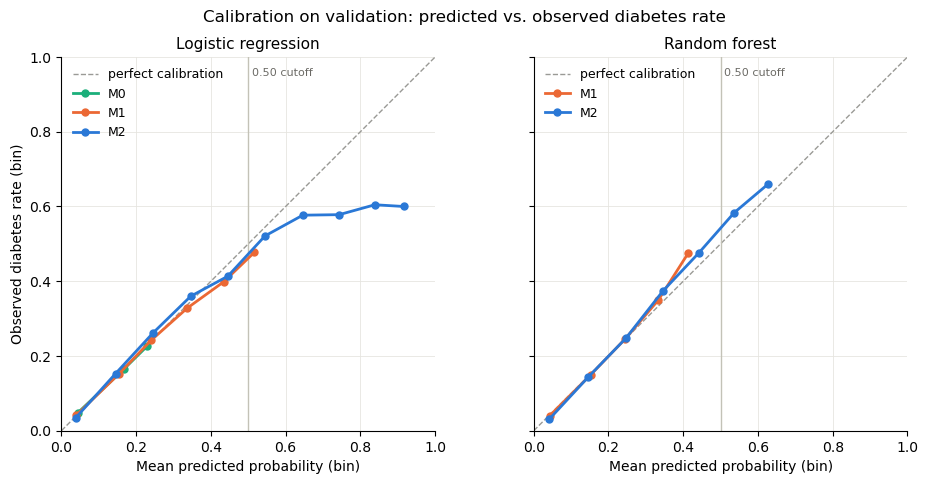

In [14]:
# Step 6c: calibration figure (validation). Same colour = same feature set in both panels.
import matplotlib.pyplot as plt
COLORS = {"M0": "#1baf7a", "M1": "#eb6834", "M2": "#2a78d6"}
fig, axes = plt.subplots(1, 2, figsize=(10, 4.8), sharex=True, sharey=True)
for ax, kind in zip(axes, ["logreg", "rf"]):
    ax.plot([0, 1], [0, 1], color="#9a9a96", lw=1, ls="--", label="perfect calibration")
    ax.axvline(CUTOFF, color="#c3c2b7", lw=1)
    ax.text(CUTOFF + 0.01, 0.97, "0.50 cutoff", fontsize=8, color="#6b6a65", va="top")
    for m in ["M0", "M1", "M2"]:
        if (m, kind) not in final:
            continue
        d = cal_bins[cal_bins["model"] == final[(m, kind)]["row"]["model"]]
        ax.plot(d["mean_predicted"], d["observed_rate"], marker="o", ms=5, lw=2, color=COLORS[m], label=m)
    ax.set_title(LABEL[kind].capitalize(), fontsize=11)
    ax.set_xlabel("Mean predicted probability (bin)")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect("equal")
    ax.grid(color="#e6e5e0", lw=0.6); ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, fontsize=9, loc="upper left")
axes[0].set_ylabel("Observed diabetes rate (bin)")
fig.suptitle("Calibration on validation: predicted vs. observed diabetes rate", fontsize=12)
fig.tight_layout()
fig.savefig(os.path.join(OUTPUTS, "fig_step6_calibration_validation.png"), dpi=200)
plt.show()

## Step 8a: SDOH comparison models, tuning and validation (module sample, TRAINING rows only)
M2 and M3 are both re-trained on the respondents who were asked the SDOH module (`has_sdoh`), with the same split.
Both are tuned with the step 5 method (decision S8a): stratified 5-fold CV on module training rows, mean ROC-AUC,
keep the default unless the best beats it by more than one SE, grids `C` in {0.01, 0.1, 1, 10} and leaf in {20, 50, 200}.
If a choice is at a grid edge, we stop and ask. Validation results and a calibration summary are development checks only.

The test evaluation of these four models is switched off (`RUN_STEP8_TEST = False`) until the tuning and validation
results have been reviewed and approved.

**Later update:** after the step 8a/8b settings were reviewed and approved, `RUN_STEP8_TEST` was set to `True`, so the step 7 cell below also scores these four models once on the test set.

In [15]:
# Step 8a: tune M2-module and M3 on module training rows (S8a); cached
RUN_STEP8_TEST = True       # approved by Catherine on 2026-11-13 after reviewing the step 8 settings
train_mod = get_part(data, "train", sdoh_only=True)
print("module training rows:", len(train_mod), "| positives:", int(train_mod["target"].sum()))
TUNE8_FILE = os.path.join(OUTPUTS, "step8_tuning_cv_results_module.csv")
if os.path.exists(TUNE8_FILE):
    tuning8 = pd.read_csv(TUNE8_FILE)
    print("Loaded cached step 8 tuning results from", TUNE8_FILE)
else:
    t_all = time.time()
    tuning8 = pd.concat([tune(m, "logreg", "C", C_GRID, df=train_mod) for m in ["M2", "M3"]]
                        + [tune(m, "rf", "min_samples_leaf", LEAF_GRID, df=train_mod) for m in ["M2", "M3"]],
                        ignore_index=True)
    tuning8.insert(0, "sample", "SDOH module")
    tuning8.to_csv(TUNE8_FILE, index=False)
    print(f"Step 8 tuning done in {(time.time() - t_all) / 60:.1f} minutes")
display(tuning8[["model", "kind", "value", "mean_ROC_AUC", "se_ROC_AUC", "mean_PR_AUC", "seconds"]].round(4))

chosen8 = pd.DataFrame([choose(g) for _, g in tuning8.groupby(["model", "kind"], sort=False)])
chosen8.to_csv(os.path.join(OUTPUTS, "step8_chosen_settings_module.csv"), index=False)
display(chosen8.round(5))
if chosen8["chosen_at_grid_edge"].any():
    print("STOP: a chosen value is at the edge of its grid. Ask before extending the grid.")
CHOSEN8 = {(r.model, r.kind): r.chosen for r in chosen8.itertuples()}
print("Step 8 settings:", CHOSEN8)

module training rows: 134963 | positives: 20878
Loaded cached step 8 tuning results from outputs/step8_tuning_cv_results_module.csv


,model,kind,value,mean_ROC_AUC,se_ROC_AUC,mean_PR_AUC,seconds
0,M2,logreg,0.01,0.8113,0.0005,0.4154,4
1,M2,logreg,0.10,0.8119,0.0006,0.4162,2
2,M2,logreg,1.00,0.8119,0.0007,0.4163,2
3,M2,logreg,10.00,0.8118,0.0007,0.4162,2
4,M3,logreg,0.01,0.8118,0.0005,0.4175,1
5,M3,logreg,0.10,0.8125,0.0006,0.4185,2
6,M3,logreg,1.00,0.8125,0.0006,0.4185,1
7,M3,logreg,10.00,0.8124,0.0006,0.4185,1
8,M2,rf,20.00,0.8112,0.0009,0.4172,19
9,M2,rf,50.00,0.8092,0.0010,0.4148,17


,model,kind,param,default,default_mean_ROC_AUC,best_value,best_mean_ROC_AUC,gain_over_default,best_SE,gain_exceeds_1SE,chosen,chosen_at_grid_edge,best_by_PR_AUC_(recorded_only)
0,M2,logreg,C,1,0.81186,0.1,0.81192,0.00006,0.00062,False,1.0,False,1.0
1,M3,logreg,C,1,0.81245,0.1,0.81249,0.00004,0.00061,False,1.0,False,1.0
2,M2,rf,min_samples_leaf,50,0.80921,20.0,0.81115,0.00194,0.00094,True,20.0,True,20.0
3,M3,rf,min_samples_leaf,50,0.80881,20.0,0.81101,0.00220,0.00105,True,20.0,True,20.0


STOP: a chosen value is at the edge of its grid. Ask before extending the grid.
Step 8 settings: {('M2', 'logreg'): 1.0, ('M3', 'logreg'): 1.0, ('M2', 'rf'): 20.0, ('M3', 'rf'): 20.0}


### Step 8b: grid extension for the two module forests (decision S8b)
Both forests chose leaf 20, the edge of the grid. As in step 5 (T2e), the grid is extended **once** with {5, 10}, with the same folds,
score and tie rule over {5, 10, 20, 50, 200} against the default 50. Stopping rule fixed in advance: if 5 wins, stop and disclose.

In [16]:
# Step 8b: extend the module forests' grid once (S8b); cached
EXT8_FILE = os.path.join(OUTPUTS, "step8b_tuning_extension_module_rf.csv")
if os.path.exists(EXT8_FILE):
    ext8 = pd.read_csv(EXT8_FILE)
    print("Loaded cached step 8b extension results from", EXT8_FILE)
else:
    ext8 = pd.concat([tune(m, "rf", "min_samples_leaf", EXT_GRID, df=train_mod) for m in ["M2", "M3"]], ignore_index=True)
    ext8.insert(0, "sample", "SDOH module")
    ext8.to_csv(EXT8_FILE, index=False)

chosen8_final = chosen8.copy()
chosen8_final["grid_extended"] = False
for m in ["M2", "M3"]:
    allv = pd.concat([ext8[ext8["model"] == m], tuning8[(tuning8["model"] == m) & (tuning8["kind"] == "rf")]],
                     ignore_index=True).sort_values("value")
    print(f"{m} forest (module), all leaf sizes:")
    display(allv[["value", "mean_ROC_AUC", "se_ROC_AUC", "mean_PR_AUC", "seconds"]].round(5))
    fin = choose(allv)
    mask = (chosen8_final["model"] == m) & (chosen8_final["kind"] == "rf")
    chosen8_final.loc[mask, list(fin)] = list(fin.values())
    chosen8_final.loc[mask, "grid_extended"] = True
    if fin["chosen_at_grid_edge"]:
        print(f"NOTE: {m} forest choice is again at the grid edge. Per S8b we stop here and disclose it.")
chosen8_final.to_csv(os.path.join(OUTPUTS, "step8_chosen_settings_module_final.csv"), index=False)
display(chosen8_final.round(5))
CHOSEN8 = {(r.model, r.kind): r.chosen for r in chosen8_final.itertuples()}
print("Final step 8 settings:", CHOSEN8)

Loaded cached step 8b extension results from outputs/step8b_tuning_extension_module_rf.csv
M2 forest (module), all leaf sizes:


,value,mean_ROC_AUC,se_ROC_AUC,mean_PR_AUC,seconds
0,5.0,0.81086,0.00094,0.41497,21
1,10.0,0.81155,0.00099,0.41709,20
2,20.0,0.81115,0.00094,0.41719,19
3,50.0,0.80921,0.00096,0.41484,17
4,200.0,0.80224,0.00081,0.40495,16


M3 forest (module), all leaf sizes:


,value,mean_ROC_AUC,se_ROC_AUC,mean_PR_AUC,seconds
0,5.0,0.81087,0.00103,0.41787,24
1,10.0,0.81159,0.00111,0.41886,23
2,20.0,0.81101,0.00105,0.41866,21
3,50.0,0.80881,0.00099,0.41523,20
4,200.0,0.80220,0.00089,0.40516,18


,model,kind,param,default,default_mean_ROC_AUC,best_value,best_mean_ROC_AUC,gain_over_default,best_SE,gain_exceeds_1SE,chosen,chosen_at_grid_edge,best_by_PR_AUC_(recorded_only),grid_extended
0,M2,logreg,C,1,0.81186,0.1,0.81192,0.00006,0.00062,False,1.0,False,1.0,False
1,M3,logreg,C,1,0.81245,0.1,0.81249,0.00004,0.00061,False,1.0,False,1.0,False
2,M2,rf,min_samples_leaf,50,0.80921,10.0,0.81155,0.00234,0.00099,True,10.0,False,20.0,True
3,M3,rf,min_samples_leaf,50,0.80881,10.0,0.81159,0.00278,0.00111,True,10.0,False,10.0,True


Final step 8 settings: {('M2', 'logreg'): 1.0, ('M3', 'logreg'): 1.0, ('M2', 'rf'): 10.0, ('M3', 'rf'): 10.0}


In [17]:
# Step 8a: refit the four models with the chosen settings on module training rows; validation (module) at 0.50 and 0.15
SPECS8 = [("M2", "logreg"), ("M3", "logreg"), ("M2", "rf"), ("M3", "rf")]
all_rows.clear()
final8 = {}
for m, kind in SPECS8:
    v = CHOSEN8[(m, kind)]
    v = int(v) if kind == "rf" else float(v)
    res = run_model(f"{m} {LABEL[kind]} (SDOH module)", MODELS[m], kind=kind, sdoh_only=True,
                    params={PARAM[kind]: v}, tag="step8")
    show(res)
    record(res, out="step8_validation_results_module.csv")
    final8[(m, kind)] = res
val8 = pd.DataFrame(all_rows)
val8_015 = pd.DataFrame([{"model": r["row"]["model"], "cutoff": SECONDARY_CUTOFF if "SECONDARY_CUTOFF" in dir() else 0.15,
                          **score(r["part"]["target"], r["p"], 0.15)} for r in final8.values()])
val8_both = pd.concat([val8.assign(cutoff=CUTOFF), val8_015])
val8_both.to_csv(os.path.join(OUTPUTS, "step8_validation_results_module_050_and_015.csv"), index=False)
display(val8_both[["model", "cutoff", "ROC-AUC", "PR-AUC", "recall", "precision", "F1", "false_pos_rate", "flagged_%"]].round(4))

# Calibration summary on module validation rows (same 10 equal-width bins as step 6)
cal8 = []
for (m, kind), res in final8.items():
    y, p = res["part"]["target"].to_numpy(), res["p"]
    b = np.minimum((p * N_BINS).astype(int), N_BINS - 1)
    for k in range(N_BINS):
        sel = b == k
        if sel.sum():
            cal8.append({"model": res["row"]["model"], "bin": f"{k/N_BINS:.1f}-{(k+1)/N_BINS:.1f}", "n": int(sel.sum()),
                         "mean_predicted": p[sel].mean(), "observed_rate": y[sel].mean(),
                         "gap_observed_minus_predicted": y[sel].mean() - p[sel].mean()})
cal8 = pd.DataFrame(cal8)
cal8.to_csv(os.path.join(OUTPUTS, "step8_calibration_bins_validation_module.csv"), index=False)
display(cal8.round(3))

M2 logistic regression (SDOH module) on val | cutoff 0.50 | fit 1s
PR-AUC 0.408 | ROC-AUC 0.807
Recall 0.148 | Precision 0.540 | F1 0.232 | FPR 0.023 | accuracy 0.848 | flagged 4.26%
Caught 446 | Missed 2568 | False alarms 380 | Cleared 15993



M3 logistic regression (SDOH module) on val | cutoff 0.50 | fit 1s
PR-AUC 0.411 | ROC-AUC 0.807
Recall 0.151 | Precision 0.546 | F1 0.236 | FPR 0.023 | accuracy 0.848 | flagged 4.29%
Caught 454 | Missed 2560 | False alarms 378 | Cleared 15995



M2 random forest (SDOH module) on val | cutoff 0.50 | fit 6s
PR-AUC 0.416 | ROC-AUC 0.809
Recall 0.064 | Precision 0.585 | F1 0.115 | FPR 0.008 | accuracy 0.847 | flagged 1.69%
Caught 192 | Missed 2822 | False alarms 136 | Cleared 16237



M3 random forest (SDOH module) on val | cutoff 0.50 | fit 6s
PR-AUC 0.417 | ROC-AUC 0.810
Recall 0.051 | Precision 0.581 | F1 0.094 | FPR 0.007 | accuracy 0.847 | flagged 1.37%
Caught 154 | Missed 2860 | False alarms 111 | Cleared 16262



,model,cutoff,ROC-AUC,PR-AUC,recall,precision,F1,false_pos_rate,flagged_%
0,M2 logistic regression (SDOH module),0.50,0.8069,0.4084,0.1480,0.5400,0.2323,0.0232,4.2606
1,M3 logistic regression (SDOH module),0.50,0.8071,0.4110,0.1506,0.5457,0.2361,0.0231,4.2915
2,M2 random forest (SDOH module),0.50,0.8095,0.4155,0.0637,0.5854,0.1149,0.0083,1.6919
3,M3 random forest (SDOH module),0.50,0.8096,0.4167,0.0511,0.5811,0.0939,0.0068,1.3669
0,M2 logistic regression (SDOH module),0.15,0.8069,0.4084,0.7896,0.3149,0.4502,0.3163,38.9900
1,M3 logistic regression (SDOH module),0.15,0.8071,0.4110,0.7843,0.3135,0.4480,0.3161,38.8920
2,M2 random forest (SDOH module),0.15,0.8095,0.4155,0.8119,0.3034,0.4418,0.3431,41.5949
3,M3 random forest (SDOH module),0.15,0.8096,0.4167,0.8215,0.3026,0.4423,0.3486,42.2087


,model,bin,n,mean_predicted,observed_rate,gap_observed_minus_predicted
0,M2 logistic regression (SDOH module),0.0-0.1,9450,0.040,0.037,-0.003
1,M2 logistic regression (SDOH module),0.1-0.2,4150,0.145,0.148,0.003
2,M2 logistic regression (SDOH module),0.2-0.3,2547,0.246,0.273,0.027
3,M2 logistic regression (SDOH module),0.3-0.4,1482,0.346,0.359,0.013
4,M2 logistic regression (SDOH module),0.4-0.5,932,0.445,0.407,-0.038
5,M2 logistic regression (SDOH module),0.5-0.6,499,0.546,0.519,-0.027
6,M2 logistic regression (SDOH module),0.6-0.7,212,0.645,0.561,-0.084
7,M2 logistic regression (SDOH module),0.7-0.8,91,0.741,0.571,-0.170
8,M2 logistic regression (SDOH module),0.8-0.9,20,0.834,0.700,-0.134
9,M2 logistic regression (SDOH module),0.9-1.0,4,0.918,0.500,-0.418


## Step 7: final test evaluation (single look)
The test file is opened **once**, in the next cell only, after all models are fit and every setting is fixed:
cutoff 0.50 (R4, R5), settings from step 5, no recalibration (C6). The leakage checks above (3–6) ran in this same session,
and checks 1–2 were rerun in `01_Data_Preprocessing.ipynb` just before. No model is fit from here on.

Test scores are cached to `outputs/scores/step7_test_*.csv`. On a rerun, the cached scores are loaded instead of re-scoring, and the
date of the first (official) evaluation is kept in `outputs/step7_test_evaluation_record.csv`.

**What the cells in this section produce:**
- Next cell (STEP 7): the test scores and `step7_test_results.csv`, plus the step 8 module models. All report numbers trace back to these saved scores.
- 0.50 confusion matrices and 0.50 subgroup recall/FPR figures: **superseded** by main Figures 1 and 2 (step 10b); kept as development output.
- Precision-recall curves (`fig_step7_pr_curves_test.png`): appendix candidate (decision FIG4).
- Within-age-band check (P4): appendix candidate (`step7_test_within_age_band_P4_appendix.csv`).

In [18]:
# STEP 7: FINAL TEST EVALUATION  (the only cell allowed to read the test file)
import datetime
assert all(r["pass"] for r in leak_results), "leakage checks must pass before the final evaluation"
pd.DataFrame(leak_results).to_csv(os.path.join(OUTPUTS, "step7_leakage_recheck_3_6.csv"), index=False)

RECORD_FILE = os.path.join(OUTPUTS, "step7_test_evaluation_record.csv")
test_df = pd.read_csv(os.path.join(DERIVED, "TEST_SET_DO_NOT_OPEN_until_final_evaluation.csv"))
assert set(test_df["split"]) == {"test"} and len(test_df) == 86793
print("test rows:", len(test_df), "| positives:", int(test_df["target"].sum()))

test_res = {}
first_run = not os.path.exists(RECORD_FILE)
for (m, kind), res in final.items():
    name = res["row"]["model"]
    f = os.path.join(SCORES_DIR, f"step7_test_{slug(name)}.csv")
    if first_run or not os.path.exists(f):
        p = res["pipe"].predict_proba(test_df[MODELS[m]])[:, 1]          # score only; no fitting
        test_df[["_STATE", "SEQNO", "split", "target"]].assign(model=name, p=p).to_csv(f, index=False)
    else:
        cached = pd.read_csv(f)
        assert (cached["SEQNO"].to_numpy() == test_df["SEQNO"].to_numpy()).all()
        p = cached["p"].to_numpy()
    row = {"model": name, "kind": kind, "set": "test", "features": len(MODELS[m]),
           "settings": res["row"]["settings"], "cutoff": CUTOFF, **score(test_df["target"], p)}
    test_res[(m, kind)] = {"part": test_df, "p": p, "threshold": CUTOFF, "row": row}

if first_run:
    pd.DataFrame([{"evaluated_on": datetime.datetime.now().isoformat(timespec="seconds"),
                   "models": "; ".join(r["row"]["model"] for r in test_res.values()),
                   "note": "single official test evaluation"}]).to_csv(RECORD_FILE, index=False)
else:
    print("Test scores loaded from cache (not re-scored). Official evaluation record:")
    print(pd.read_csv(RECORD_FILE).to_string(index=False))

test_results = pd.DataFrame([r["row"] for r in test_res.values()])
test_results.to_csv(os.path.join(OUTPUTS, "step7_test_results.csv"), index=False)
show_cols = ["model", "settings", "recall", "precision", "F1", "ROC-AUC", "PR-AUC", "false_pos_rate",
             "accuracy", "flagged_%", "caught", "missed", "false_alarms", "cleared"]
display(test_results[show_cols].round(3))

# ---- Step 8 models (SDOH comparison): scored once on test respondents asked the SDOH module (S8a, S8b) ----
test_res8 = {}
if RUN_STEP8_TEST:
    REC8 = os.path.join(OUTPUTS, "step8_test_evaluation_record.csv")
    first8 = not os.path.exists(REC8)
    test_mod = test_df[test_df["has_sdoh"]].reset_index(drop=True)
    print("module test rows:", len(test_mod), "| positives:", int(test_mod["target"].sum()))
    for (m, kind), res in final8.items():
        name = res["row"]["model"]
        f = os.path.join(SCORES_DIR, f"step8_test_{slug(name)}.csv")
        if first8 or not os.path.exists(f):
            p = res["pipe"].predict_proba(test_mod[MODELS[m]])[:, 1]          # score only; no fitting
            test_mod[["_STATE", "SEQNO", "split", "target"]].assign(model=name, p=p).to_csv(f, index=False)
        else:
            cached = pd.read_csv(f)
            assert (cached["SEQNO"].to_numpy() == test_mod["SEQNO"].to_numpy()).all()
            p = cached["p"].to_numpy()
        test_res8[(m, kind)] = {"part": test_mod, "p": p, "threshold": CUTOFF,
                                "row": {"model": name, "kind": kind, "set": "test (SDOH module)",
                                        "features": len(MODELS[m]), "settings": res["row"]["settings"],
                                        "cutoff": CUTOFF, **score(test_mod["target"], p)}}
    if first8:
        pd.DataFrame([{"evaluated_on": datetime.datetime.now().isoformat(timespec="seconds"),
                       "models": "; ".join(r["row"]["model"] for r in test_res8.values()),
                       "note": "single official test evaluation of the step 8 (SDOH comparison) models"}]
                    ).to_csv(REC8, index=False)
    else:
        print("Step 8 test scores loaded from cache (not re-scored). Official record:")
        print(pd.read_csv(REC8).to_string(index=False))

test rows: 86793 | positives: 12964


Test scores loaded from cache (not re-scored). Official evaluation record:
       evaluated_on                                                                                                     models                            note
2026-11-13T15:02:36 M0 logistic regression; M1 logistic regression; M2 logistic regression; M1 random forest; M2 random forest single official test evaluation


,model,settings,recall,precision,F1,ROC-AUC,PR-AUC,false_pos_rate,accuracy,flagged_%,caught,missed,false_alarms,cleared
0,M0 logistic regression,{'C': 1.0},0.000,NaN,NaN,0.688,0.236,0.000,0.851,0.000,0,12964,0,73829
1,M1 logistic regression,{'C': 1.0},0.004,0.490,0.007,0.733,0.293,0.001,0.851,0.111,47,12917,49,73780
2,M2 logistic regression,{'C': 1.0},0.147,0.540,0.231,0.817,0.413,0.022,0.854,4.071,1908,11056,1625,72204
3,M1 random forest,{'min_samples_leaf': 50},0.000,NaN,NaN,0.738,0.301,0.000,0.851,0.000,0,12964,0,73829
4,M2 random forest,{'min_samples_leaf': 10},0.070,0.588,0.125,0.820,0.420,0.009,0.854,1.775,906,12058,635,73194


module test rows: 38356 | positives: 5920
Step 8 test scores loaded from cache (not re-scored). Official record:
       evaluated_on                                                                                                                                     models                                                                   note
2026-11-13T15:40:56 M2 logistic regression (SDOH module); M3 logistic regression (SDOH module); M2 random forest (SDOH module); M3 random forest (SDOH module) single official test evaluation of the step 8 (SDOH comparison) models


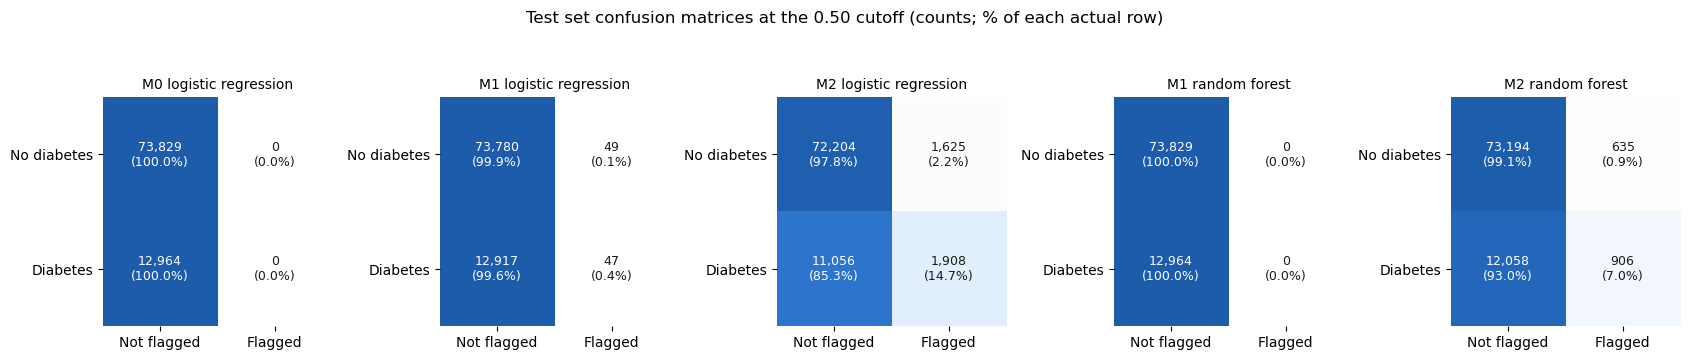

In [19]:
# Step 7: confusion matrices at the 0.50 cutoff (main figure, TA request)
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
BLUES = LinearSegmentedColormap.from_list("ramp", ["#ffffff", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab"])
order = [("M0", "logreg"), ("M1", "logreg"), ("M2", "logreg"), ("M1", "rf"), ("M2", "rf")]
fig, axes = plt.subplots(1, 5, figsize=(17, 3.9))
cm_rows = []
for ax, key in zip(axes, order):
    r = test_res[key]["row"]
    cm = np.array([[r["cleared"], r["false_alarms"]], [r["missed"], r["caught"]]])   # rows: actual no/yes; cols: flagged no/yes
    row_pct = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(row_pct, cmap=BLUES, vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}\n({100 * row_pct[i, j]:.1f}%)", ha="center", va="center", fontsize=9,
                    color="white" if row_pct[i, j] > 0.6 else "#1a1a19")
    ax.set_xticks([0, 1], ["Not flagged", "Flagged"]); ax.set_yticks([0, 1], ["No diabetes", "Diabetes"])
    ax.set_title(f"{key[0]} {LABEL[key[1]]}", fontsize=10)
    for s in ax.spines.values(): s.set_visible(False)
    cm_rows.append({"model": r["model"], "TN_cleared": r["cleared"], "FP_false_alarms": r["false_alarms"],
                    "FN_missed": r["missed"], "TP_caught": r["caught"]})
fig.suptitle("Test set confusion matrices at the 0.50 cutoff (counts; % of each actual row)", fontsize=12)
fig.tight_layout()
fig.savefig(os.path.join(OUTPUTS, "fig_step7_confusion_matrices_test.png"), dpi=200)
pd.DataFrame(cm_rows).to_csv(os.path.join(OUTPUTS, "fig_step7_confusion_matrices_test.csv"), index=False)
plt.show()

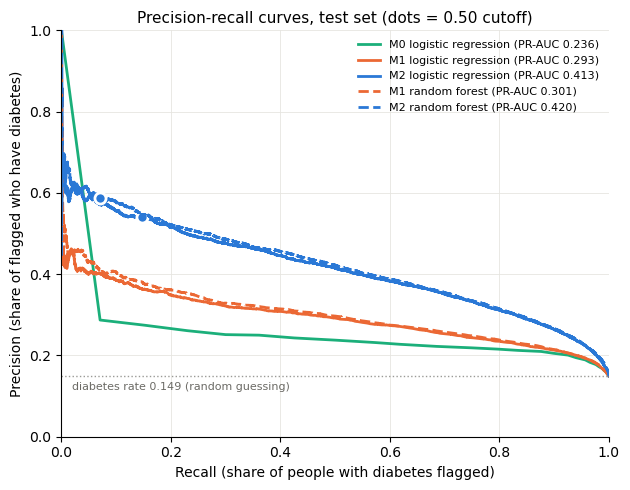

In [20]:
# Step 7: precision-recall curves on the test set; the dot marks each model's 0.50 operating point
from sklearn.metrics import precision_recall_curve
COLORS = {"M0": "#1baf7a", "M1": "#eb6834", "M2": "#2a78d6"}
STYLE = {"logreg": "-", "rf": "--"}
fig, ax = plt.subplots(figsize=(6.4, 5))
pr_rows = []
y_test = test_df["target"].to_numpy()
for key in order:
    m, kind = key
    r = test_res[key]
    prec, rec, _ = precision_recall_curve(y_test, r["p"])
    ax.plot(rec, prec, ls=STYLE[kind], lw=2, color=COLORS[m],
            label=f"{m} {LABEL[kind]} (PR-AUC {r['row']['PR-AUC']:.3f})")
    if r["row"]["caught"] > 0:
        ax.plot(r["row"]["recall"], r["row"]["precision"], "o", ms=8, color=COLORS[m], mec="white", mew=2)
    pr_rows.append(pd.DataFrame({"model": r["row"]["model"], "recall": rec, "precision": prec}).iloc[::50])
ax.axhline(y_test.mean(), color="#9a9a96", lw=1, ls=":")
ax.text(0.02, y_test.mean() - 0.035, f"diabetes rate {y_test.mean():.3f} (random guessing)", ha="left", fontsize=8, color="#6b6a65")
ax.set_xlabel("Recall (share of people with diabetes flagged)")
ax.set_ylabel("Precision (share of flagged who have diabetes)")
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.grid(color="#e6e5e0", lw=0.6); ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=8, loc="upper right")
ax.set_title("Precision-recall curves, test set (dots = 0.50 cutoff)", fontsize=11)
fig.tight_layout()
fig.savefig(os.path.join(OUTPUTS, "fig_step7_pr_curves_test.png"), dpi=200)
pd.concat(pr_rows).to_csv(os.path.join(OUTPUTS, "fig_step7_pr_curves_test.csv"), index=False)
plt.show()

M2 logistic regression


,grouping,group,n,positives,prevalence,recall,precision,false_pos_rate,flagged_%,ROC-AUC
38,grp_age,18-34,15560,310,0.020,0.003,1.000,0.000,0.006,0.756
39,grp_age,35-49,17079,1294,0.076,0.044,0.548,0.003,0.609,0.818
40,grp_age,50-64,21347,3900,0.183,0.147,0.546,0.027,4.914,0.782
41,grp_age,65+,32807,7460,0.227,0.171,0.537,0.043,7.252,0.740
42,grp_sex,Female,45282,6544,0.145,0.123,0.526,0.019,3.381,0.810
43,grp_sex,Male,41511,6420,0.155,0.172,0.551,0.026,4.823,0.825
44,grp_race,Black,6613,1465,0.222,0.236,0.593,0.046,8.816,0.801
45,grp_race,Hispanic,9183,1348,0.147,0.228,0.593,0.027,5.641,0.860
46,grp_race,Multiracial,2023,288,0.142,0.167,0.516,0.026,4.597,0.848
47,grp_race,Other race,4544,711,0.156,0.193,0.527,0.032,5.722,0.827


M2 random forest


,grouping,group,n,positives,prevalence,recall,precision,false_pos_rate,flagged_%,ROC-AUC
76,grp_age,18-34,15560,310,0.020,0.000,NaN,0.000,0.000,0.783
77,grp_age,35-49,17079,1294,0.076,0.008,0.667,0.000,0.088,0.824
78,grp_age,50-64,21347,3900,0.183,0.077,0.590,0.012,2.389,0.788
79,grp_age,65+,32807,7460,0.227,0.080,0.586,0.017,3.097,0.745
80,grp_sex,Female,45282,6544,0.145,0.055,0.559,0.007,1.422,0.814
81,grp_sex,Male,41511,6420,0.155,0.085,0.609,0.010,2.161,0.826
82,grp_race,Black,6613,1465,0.222,0.095,0.641,0.015,3.281,0.804
83,grp_race,Hispanic,9183,1348,0.147,0.088,0.590,0.010,2.178,0.862
84,grp_race,Multiracial,2023,288,0.142,0.087,0.658,0.007,1.878,0.855
85,grp_race,Other race,4544,711,0.156,0.065,0.630,0.007,1.607,0.835


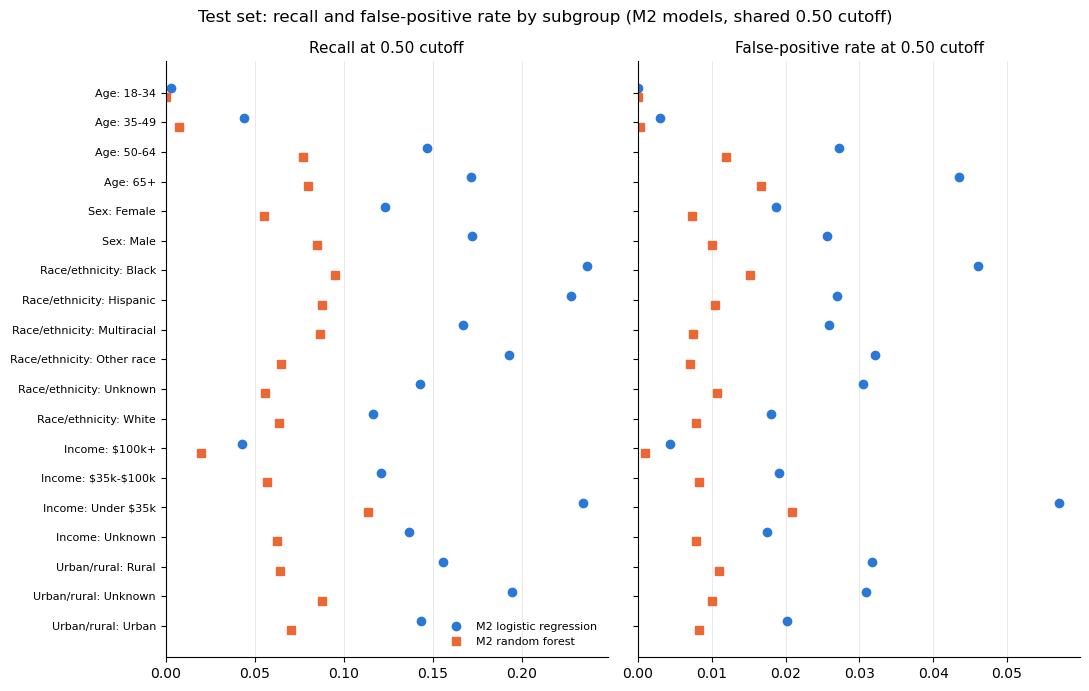

In [21]:
# Step 7: subgroup audit on the test set, same 0.50 cutoff for every group (R5)
groups_test = pd.concat([by_group(test_res[k]) for k in order], ignore_index=True)
groups_test.to_csv(os.path.join(OUTPUTS, "step7_test_by_group.csv"), index=False)
gcols = ["grouping", "group", "n", "positives", "prevalence", "recall", "precision", "false_pos_rate", "flagged_%", "ROC-AUC"]
for name in ["M2 logistic regression", "M2 random forest"]:
    print(name)
    display(groups_test[groups_test["model"] == name][gcols].round(3))

# Figure: recall and false-positive rate by subgroup for the two M2 models
GROUP_TITLES = {"grp_age": "Age", "grp_sex": "Sex", "grp_race": "Race/ethnicity", "grp_income": "Income", "grp_urban": "Urban/rural"}
sub = groups_test[groups_test["model"].isin(["M2 logistic regression", "M2 random forest"])].copy()
sub["label"] = sub["grouping"].map(GROUP_TITLES) + ": " + sub["group"].astype(str).str.replace("$", r"\$", regex=False)   # stop $ being read as math
labels = list(dict.fromkeys(sub["label"]))[::-1]
ypos = {l: i for i, l in enumerate(labels)}
MK = {"M2 logistic regression": ("#2a78d6", "o"), "M2 random forest": ("#eb6834", "s")}
fig, axes = plt.subplots(1, 2, figsize=(11, 7), sharey=True)
for ax, metric, title in zip(axes, ["recall", "false_pos_rate"], ["Recall", "False-positive rate"]):
    for name, (c, mk) in MK.items():
        d = sub[sub["model"] == name]
        off = 0.15 if mk == "o" else -0.15
        ax.plot(d[metric], [ypos[l] + off for l in d["label"]], mk, color=c, ms=6, label=name, ls="none")
    ax.set_title(title + " at 0.50 cutoff", fontsize=11)
    ax.grid(axis="x", color="#e6e5e0", lw=0.6); ax.spines[["top", "right"]].set_visible(False)
    ax.set_xlim(left=0)
axes[0].set_yticks(range(len(labels)), labels, fontsize=8)
axes[0].legend(frameon=False, fontsize=8, loc="lower right")
fig.suptitle("Test set: recall and false-positive rate by subgroup (M2 models, shared 0.50 cutoff)", fontsize=12)
fig.tight_layout()
fig.savefig(os.path.join(OUTPUTS, "fig_step7_subgroup_recall_fpr_test.png"), dpi=200)
sub[["model", "grouping", "group", "n", "positives", "prevalence", "recall", "false_pos_rate"]].to_csv(
    os.path.join(OUTPUTS, "fig_step7_subgroup_recall_fpr_test.csv"), index=False)
plt.show()

In [22]:
# Step 7 (P4, appendix only): within-age-band check, M2 models, same test predictions and 0.50 cutoff
MIN_POS = 50   # cells with fewer people with diabetes are shown but not interpreted (P4)
BANDS = {"18-34": "18-49", "35-49": "18-49", "50-64": "50-64", "65+": "65+"}
p4_rows = []
for key in [("M2", "logreg"), ("M2", "rf")]:
    r = test_res[key]
    tmp = test_df.assign(p=r["p"], age_band=test_df["grp_age"].map(BANDS))
    for by in ["grp_income", "grp_race"]:
        for (band, g), d in tmp.groupby(["age_band", by]):
            p4_rows.append({"model": r["row"]["model"], "age_band": band, "grouping": by, "group": g,
                            **score(d["target"], d["p"]),
                            "interpretable": int(d["target"].sum()) >= MIN_POS})
p4 = pd.DataFrame(p4_rows)
p4.to_csv(os.path.join(OUTPUTS, "step7_test_within_age_band_P4_appendix.csv"), index=False)
pcols = ["model", "age_band", "grouping", "group", "n", "positives", "prevalence", "recall", "false_pos_rate", "interpretable"]
display(p4[p4["model"] == "M2 logistic regression"][pcols].round(3))

,model,age_band,grouping,group,n,positives,prevalence,recall,false_pos_rate,interpretable
0,M2 logistic regression,18-49,grp_income,$100k+,9632,334,0.035,0.009,0.001,True
1,M2 logistic regression,18-49,grp_income,$35k-$100k,11489,559,0.049,0.034,0.002,True
2,M2 logistic regression,18-49,grp_income,Under $35k,6141,483,0.079,0.066,0.004,True
3,M2 logistic regression,18-49,grp_income,Unknown,5377,228,0.042,0.018,0.000,True
4,M2 logistic regression,50-64,grp_income,$100k+,7065,842,0.119,0.033,0.005,True
5,M2 logistic regression,50-64,grp_income,$35k-$100k,6910,1240,0.179,0.118,0.022,True
6,M2 logistic regression,50-64,grp_income,Under $35k,4270,1252,0.293,0.255,0.085,True
7,M2 logistic regression,50-64,grp_income,Unknown,3102,566,0.182,0.141,0.024,True
8,M2 logistic regression,65+,grp_income,$100k+,5134,789,0.154,0.067,0.011,True
9,M2 logistic regression,65+,grp_income,$35k-$100k,12711,2816,0.222,0.140,0.036,True


## Step 7b: secondary cutoff 0.15 (decision R7a, added after the 0.50 results)
**0.50 remains the primary result.** 0.15 is approximately the training-set diabetes rate (14.9%), so it means
"flag anyone whose predicted risk is above the average respondent's". It was added after the 0.50 test results had been seen
(disclosed). It uses the **test predictions saved in step 7**: no model is refit, nothing is tuned, and the test file is not re-read.

**Later update (R7b):** for presentation, the report later made **0.15 the main cutoff**, with 0.50 reported alongside everywhere. The order of events above is unchanged and disclosed.
The step 7b figures in this section are **superseded** by main Figures 1 and 2; the metrics table (`step7b_test_results_050_vs_015.csv`) is still used.

In [23]:
# Step 7b (R7a): metrics at the secondary 0.15 cutoff, from the saved step 7 test predictions
import datetime
SECONDARY_CUTOFF = 0.15
REC_B = os.path.join(OUTPUTS, "step7b_cutoff015_record.csv")
if not os.path.exists(REC_B):
    pd.DataFrame([{"computed_on": datetime.datetime.now().isoformat(timespec="seconds"),
                   "note": "R7a secondary 0.15 cutoff on saved step 7 test predictions (additional look, disclosed)"}]
                ).to_csv(REC_B, index=False)

test_res_015 = {k: {**v, "threshold": SECONDARY_CUTOFF,
                    "row": {**{c: v["row"][c] for c in ["model", "kind", "set", "features", "settings"]},
                            "cutoff": SECONDARY_CUTOFF, **score(v["part"]["target"], v["p"], SECONDARY_CUTOFF)}}
                for k, v in test_res.items()}
res015 = pd.DataFrame([r["row"] for r in test_res_015.values()])
res015.to_csv(os.path.join(OUTPUTS, "step7b_test_results_cutoff015.csv"), index=False)
display(res015[show_cols].round(3))

# side by side with the primary 0.50 results
both = pd.concat([test_results.assign(cutoff=CUTOFF), res015])[["model", "cutoff", "recall", "precision", "F1",
        "false_pos_rate", "accuracy", "flagged_%", "caught", "missed", "false_alarms"]]
both.to_csv(os.path.join(OUTPUTS, "step7b_test_results_050_vs_015.csv"), index=False)
display(both.sort_values(["model", "cutoff"], ascending=[True, False]).round(3))

groups_015 = pd.concat([by_group(test_res_015[k]) for k in order], ignore_index=True)
groups_015.to_csv(os.path.join(OUTPUTS, "step7b_test_by_group_cutoff015.csv"), index=False)
for name in ["M2 logistic regression", "M2 random forest"]:
    print(name, "at 0.15")
    display(groups_015[groups_015["model"] == name][gcols].round(3))

,model,settings,recall,precision,F1,ROC-AUC,PR-AUC,false_pos_rate,accuracy,flagged_%,caught,missed,false_alarms,cleared
0,M0 logistic regression,{'C': 1.0},0.834,0.212,0.339,0.688,0.236,0.543,0.513,58.640,10811,2153,40084,33745
1,M1 logistic regression,{'C': 1.0},0.793,0.235,0.363,0.733,0.293,0.453,0.584,50.398,10283,2681,33459,40370
2,M2 logistic regression,{'C': 1.0},0.789,0.315,0.450,0.817,0.413,0.302,0.712,37.453,10235,2729,22272,51557
3,M1 random forest,{'min_samples_leaf': 50},0.798,0.239,0.367,0.738,0.301,0.447,0.589,49.987,10348,2616,33037,40792
4,M2 random forest,{'min_samples_leaf': 10},0.818,0.306,0.446,0.820,0.420,0.325,0.696,39.890,10604,2360,24018,49811


,model,cutoff,recall,precision,F1,false_pos_rate,accuracy,flagged_%,caught,missed,false_alarms
0,M0 logistic regression,0.50,0.000,NaN,NaN,0.000,0.851,0.000,0,12964,0
0,M0 logistic regression,0.15,0.834,0.212,0.339,0.543,0.513,58.640,10811,2153,40084
1,M1 logistic regression,0.50,0.004,0.490,0.007,0.001,0.851,0.111,47,12917,49
1,M1 logistic regression,0.15,0.793,0.235,0.363,0.453,0.584,50.398,10283,2681,33459
3,M1 random forest,0.50,0.000,NaN,NaN,0.000,0.851,0.000,0,12964,0
3,M1 random forest,0.15,0.798,0.239,0.367,0.447,0.589,49.987,10348,2616,33037
2,M2 logistic regression,0.50,0.147,0.540,0.231,0.022,0.854,4.071,1908,11056,1625
2,M2 logistic regression,0.15,0.789,0.315,0.450,0.302,0.712,37.453,10235,2729,22272
4,M2 random forest,0.50,0.070,0.588,0.125,0.009,0.854,1.775,906,12058,635
4,M2 random forest,0.15,0.818,0.306,0.446,0.325,0.696,39.890,10604,2360,24018


M2 logistic regression at 0.15


,grouping,group,n,positives,prevalence,recall,precision,false_pos_rate,flagged_%,ROC-AUC
38,grp_age,18-34,15560,310,0.020,0.110,0.218,0.008,1.003,0.756
39,grp_age,35-49,17079,1294,0.076,0.498,0.281,0.104,13.420,0.818
40,grp_age,50-64,21347,3900,0.183,0.801,0.318,0.384,46.021,0.782
41,grp_age,65+,32807,7460,0.227,0.862,0.318,0.545,61.679,0.740
42,grp_sex,Female,45282,6544,0.145,0.758,0.309,0.287,35.526,0.810
43,grp_sex,Male,41511,6420,0.155,0.821,0.321,0.318,39.556,0.825
44,grp_race,Black,6613,1465,0.222,0.877,0.367,0.431,52.987,0.801
45,grp_race,Hispanic,9183,1348,0.147,0.812,0.373,0.235,31.939,0.860
46,grp_race,Multiracial,2023,288,0.142,0.806,0.348,0.251,32.971,0.848
47,grp_race,Other race,4544,711,0.156,0.814,0.337,0.297,37.786,0.827


M2 random forest at 0.15


,grouping,group,n,positives,prevalence,recall,precision,false_pos_rate,flagged_%,ROC-AUC
76,grp_age,18-34,15560,310,0.020,0.223,0.131,0.030,3.374,0.783
77,grp_age,35-49,17079,1294,0.076,0.658,0.238,0.172,20.897,0.824
78,grp_age,50-64,21347,3900,0.183,0.820,0.318,0.392,47.042,0.788
79,grp_age,65+,32807,7460,0.227,0.869,0.317,0.552,62.444,0.745
80,grp_sex,Female,45282,6544,0.145,0.798,0.297,0.319,38.821,0.814
81,grp_sex,Male,41511,6420,0.155,0.838,0.316,0.332,41.057,0.826
82,grp_race,Black,6613,1465,0.222,0.902,0.363,0.450,55.028,0.804
83,grp_race,Hispanic,9183,1348,0.147,0.827,0.369,0.244,32.930,0.862
84,grp_race,Multiracial,2023,288,0.142,0.865,0.327,0.295,37.617,0.855
85,grp_race,Other race,4544,711,0.156,0.823,0.349,0.284,36.840,0.835


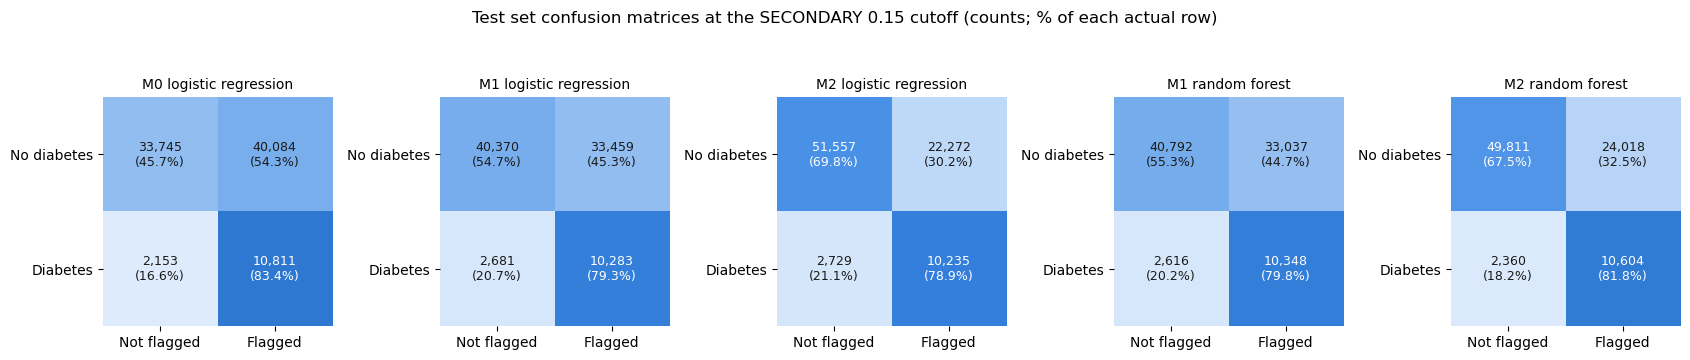

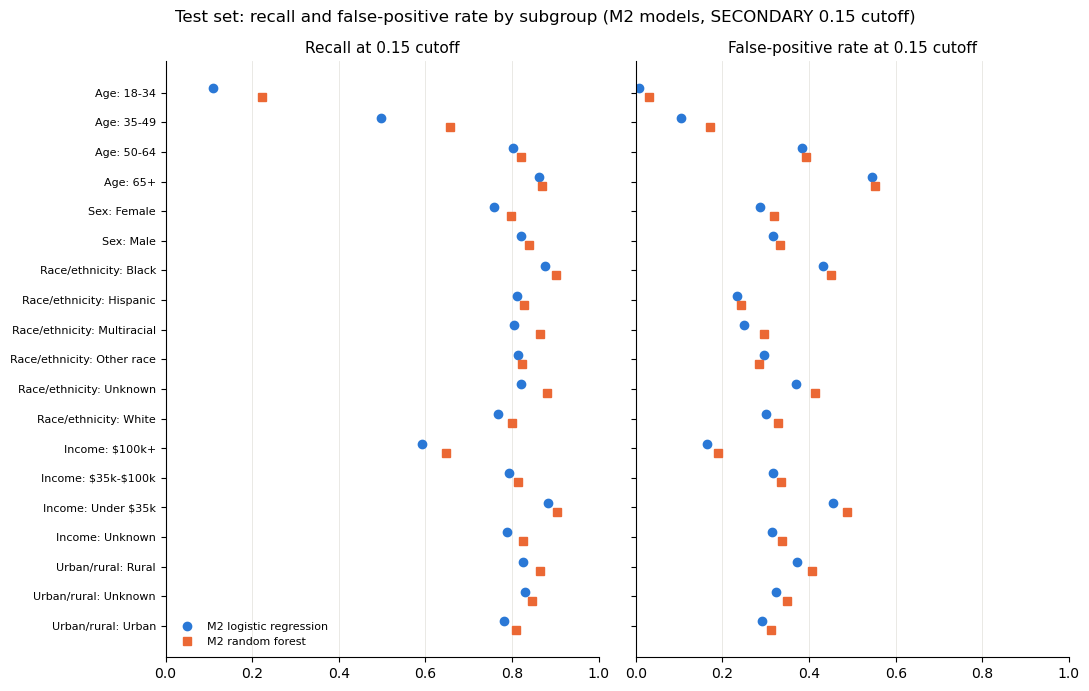

In [24]:
# Step 7b figures at 0.15: confusion matrices, and subgroup recall / FPR (same designs as the 0.50 figures)
fig, axes = plt.subplots(1, 5, figsize=(17, 3.9))
cm_rows = []
for ax, key in zip(axes, order):
    r = test_res_015[key]["row"]
    cm = np.array([[r["cleared"], r["false_alarms"]], [r["missed"], r["caught"]]])
    row_pct = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(row_pct, cmap=BLUES, vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}\n({100 * row_pct[i, j]:.1f}%)", ha="center", va="center", fontsize=9,
                    color="white" if row_pct[i, j] > 0.6 else "#1a1a19")
    ax.set_xticks([0, 1], ["Not flagged", "Flagged"]); ax.set_yticks([0, 1], ["No diabetes", "Diabetes"])
    ax.set_title(f"{key[0]} {LABEL[key[1]]}", fontsize=10)
    for s in ax.spines.values(): s.set_visible(False)
    cm_rows.append({"model": r["model"], "TN_cleared": r["cleared"], "FP_false_alarms": r["false_alarms"],
                    "FN_missed": r["missed"], "TP_caught": r["caught"]})
fig.suptitle("Test set confusion matrices at the SECONDARY 0.15 cutoff (counts; % of each actual row)", fontsize=12)
fig.tight_layout()
fig.savefig(os.path.join(OUTPUTS, "fig_step7b_confusion_matrices_test_cutoff015.png"), dpi=200)
pd.DataFrame(cm_rows).to_csv(os.path.join(OUTPUTS, "fig_step7b_confusion_matrices_test_cutoff015.csv"), index=False)
plt.show()

sub = groups_015[groups_015["model"].isin(["M2 logistic regression", "M2 random forest"])].copy()
sub["label"] = (sub["grouping"].map(GROUP_TITLES) + ": " + sub["group"].astype(str)).str.replace("$", r"\$", regex=False)
labels = list(dict.fromkeys(sub["label"]))[::-1]
ypos = {l: i for i, l in enumerate(labels)}
fig, axes = plt.subplots(1, 2, figsize=(11, 7), sharey=True)
for ax, metric, title in zip(axes, ["recall", "false_pos_rate"], ["Recall", "False-positive rate"]):
    for name, (c, mk) in MK.items():
        d = sub[sub["model"] == name]
        off = 0.15 if mk == "o" else -0.15
        ax.plot(d[metric], [ypos[l] + off for l in d["label"]], mk, color=c, ms=6, label=name, ls="none")
    ax.set_title(title + " at 0.15 cutoff", fontsize=11)
    ax.grid(axis="x", color="#e6e5e0", lw=0.6); ax.spines[["top", "right"]].set_visible(False)
    ax.set_xlim(0, 1)
axes[0].set_yticks(range(len(labels)), labels, fontsize=8)
axes[0].legend(frameon=False, fontsize=8, loc="lower left")
fig.suptitle("Test set: recall and false-positive rate by subgroup (M2 models, SECONDARY 0.15 cutoff)", fontsize=12)
fig.tight_layout()
fig.savefig(os.path.join(OUTPUTS, "fig_step7b_subgroup_recall_fpr_test_cutoff015.png"), dpi=200)
sub[["model", "grouping", "group", "n", "positives", "prevalence", "recall", "false_pos_rate"]].to_csv(
    os.path.join(OUTPUTS, "fig_step7b_subgroup_recall_fpr_test_cutoff015.csv"), index=False)
plt.show()

## Step 8: does adding SDOH items help? M2-module vs M3 on the SDOH-module test respondents
Same respondents, same split, same settings for both sides (S8a, S8b). Primary cutoff 0.50, secondary 0.15 (R7a).
Proposal rule: SDOH "helps" only if M3 improves **recall and PR-AUC** over M2 **overall and within subgroups**; otherwise we report
that it adds little. Without confidence intervals (R8), every difference is descriptive.

**What the cells in this section produce:** the M3-minus-M2 tables used for Table 2 and the results text; the M3-minus-M2 figure and the 8-panel confusion matrices (`fig_step8_*`) are appendix candidates. The main-report version is Figure 3 (step 10b, logistic regression at 0.15).

In [25]:
# Step 8: overall comparison at 0.50 and 0.15, and M3 minus M2
assert RUN_STEP8_TEST and test_res8, "step 8 test evaluation is switched off"
rows8 = []
for (m, kind), r in test_res8.items():
    for cut in [CUTOFF, 0.15]:
        rows8.append({"model": m, "kind": kind, "cutoff": cut, "n": len(r["part"]),
                      **{k: v for k, v in score(r["part"]["target"], r["p"], cut).items() if k not in ("n",)}})
res8 = pd.DataFrame(rows8)
res8.to_csv(os.path.join(OUTPUTS, "step8_test_results_module.csv"), index=False)
mcols = ["PR-AUC", "ROC-AUC", "recall", "precision", "F1", "false_pos_rate", "flagged_%", "caught", "false_alarms"]
display(res8[["model", "kind", "cutoff"] + mcols].round(4))

diff8 = []
for kind in ["logreg", "rf"]:
    for cut in [CUTOFF, 0.15]:
        a = res8[(res8["model"] == "M2") & (res8["kind"] == kind) & (res8["cutoff"] == cut)].iloc[0]
        b = res8[(res8["model"] == "M3") & (res8["kind"] == kind) & (res8["cutoff"] == cut)].iloc[0]
        diff8.append({"kind": kind, "cutoff": cut, **{f"{c} (M3-M2)": b[c] - a[c] for c in mcols}})
diff8 = pd.DataFrame(diff8)
diff8.to_csv(os.path.join(OUTPUTS, "step8_test_M3_minus_M2_overall.csv"), index=False)
display(diff8.round(4))

,model,kind,cutoff,PR-AUC,ROC-AUC,recall,precision,F1,false_pos_rate,flagged_%,caught,false_alarms
0,M2,logreg,0.50,0.4182,0.8145,0.1468,0.5358,0.2304,0.0232,4.2288,869,753
1,M2,logreg,0.15,0.4182,0.8145,0.7976,0.3170,0.4537,0.3137,38.8362,4722,10174
2,M3,logreg,0.50,0.4191,0.8145,0.1488,0.5385,0.2332,0.0233,4.2653,881,755
3,M3,logreg,0.15,0.4191,0.8145,0.8002,0.3185,0.4556,0.3125,38.7788,4737,10137
4,M2,rf,0.50,0.4240,0.8161,0.0671,0.5908,0.1204,0.0085,1.7520,397,275
5,M2,rf,0.15,0.4240,0.8161,0.8257,0.3058,0.4463,0.3421,41.6754,4888,11097
6,M3,rf,0.50,0.4253,0.8162,0.0535,0.6038,0.0984,0.0064,1.3688,317,208
7,M3,rf,0.15,0.4253,0.8162,0.8319,0.3044,0.4457,0.3470,42.1811,4925,11254


,kind,cutoff,PR-AUC (M3-M2),ROC-AUC (M3-M2),recall (M3-M2),precision (M3-M2),F1 (M3-M2),false_pos_rate (M3-M2),flagged_% (M3-M2),caught (M3-M2),false_alarms (M3-M2)
0,logreg,0.50,0.0009,-0.0000,0.0020,0.0028,0.0027,0.0001,0.0365,12,2
1,logreg,0.15,0.0009,-0.0000,0.0025,0.0015,0.0019,-0.0011,-0.0574,15,-37
2,rf,0.50,0.0014,0.0001,-0.0135,0.0130,-0.0221,-0.0021,-0.3833,-80,-67
3,rf,0.15,0.0014,0.0001,0.0062,-0.0014,-0.0006,0.0048,0.5058,37,157


In [26]:
# Step 8: subgroups (same cutoff for every group), M3 minus M2, and the proposal's rule applied descriptively
g8 = []
for (m, kind), r in test_res8.items():
    for cut in [CUTOFF, 0.15]:
        g = by_group({**r, "threshold": cut})
        g8.append(g.assign(model_set=m, kind=kind, cutoff=cut))
g8 = pd.concat(g8, ignore_index=True)
g8.to_csv(os.path.join(OUTPUTS, "step8_test_by_group_module.csv"), index=False)

keys = ["kind", "cutoff", "grouping", "group"]
a = g8[g8["model_set"] == "M2"].set_index(keys)
b = g8[g8["model_set"] == "M3"].set_index(keys)
side = a[["n", "positives", "prevalence"]].copy()
for c in ["recall", "PR-AUC", "ROC-AUC", "false_pos_rate", "precision"]:
    side[f"{c} M2"] = a[c]; side[f"{c} M3"] = b[c]; side[f"{c} M3-M2"] = b[c] - a[c]
side = side.reset_index()
side.to_csv(os.path.join(OUTPUTS, "step8_test_by_group_M2_vs_M3.csv"), index=False)

# Proposal rule (descriptive): does M3 improve BOTH recall and PR-AUC, overall and in each subgroup?
rule = []
for kind in ["logreg", "rf"]:
    for cut in [CUTOFF, 0.15]:
        o = diff8[(diff8["kind"] == kind) & (diff8["cutoff"] == cut)].iloc[0]
        s = side[(side["kind"] == kind) & (side["cutoff"] == cut)]
        both = (s["recall M3-M2"] > 0) & (s["PR-AUC M3-M2"] > 0)
        rule.append({"kind": kind, "cutoff": cut,
                     "overall recall up": o["recall (M3-M2)"] > 0, "overall PR-AUC up": o["PR-AUC (M3-M2)"] > 0,
                     "subgroups with both up": int(both.sum()), "subgroups": len(s),
                     "largest |recall change| in a subgroup": s["recall M3-M2"].abs().max(),
                     "largest |PR-AUC change| in a subgroup": s["PR-AUC M3-M2"].abs().max()})
rule = pd.DataFrame(rule)
rule.to_csv(os.path.join(OUTPUTS, "step8_test_proposal_rule_check.csv"), index=False)
display(rule.round(4))
show8 = ["grouping", "group", "positives", "recall M2", "recall M3", "recall M3-M2", "PR-AUC M2", "PR-AUC M3", "PR-AUC M3-M2"]
for kind in ["logreg", "rf"]:
    print(LABEL[kind], "at 0.50")
    display(side[(side["kind"] == kind) & (side["cutoff"] == CUTOFF)][show8].round(4))

,kind,cutoff,overall recall up,overall PR-AUC up,subgroups with both up,subgroups,largest |recall change| in a subgroup,largest |PR-AUC change| in a subgroup
0,logreg,0.50,True,True,9,19,0.0163,0.0156
1,logreg,0.15,True,True,8,19,0.0163,0.0156
2,rf,0.50,False,True,1,19,0.0287,0.0116
3,rf,0.15,True,True,13,19,0.0488,0.0116


logistic regression at 0.50


,grouping,group,positives,recall M2,recall M3,recall M3-M2,PR-AUC M2,PR-AUC M3,PR-AUC M3-M2
0,grp_age,18-34,123,0.0000,0.0000,0.0000,0.1464,0.1461,-0.0004
1,grp_age,35-49,604,0.0331,0.0397,0.0066,0.2948,0.2965,0.0017
2,grp_age,50-64,1733,0.1477,0.1541,0.0063,0.4254,0.4265,0.0011
3,grp_age,65+,3460,0.1714,0.1705,-0.0009,0.4392,0.4402,0.0010
4,grp_sex,Female,3039,0.1244,0.1283,0.0039,0.4087,0.4090,0.0003
5,grp_sex,Male,2881,0.1704,0.1704,0.0000,0.4289,0.4304,0.0015
6,grp_race,Black,785,0.2318,0.2357,0.0038,0.5117,0.5105,-0.0011
7,grp_race,Hispanic,620,0.2065,0.2113,0.0048,0.5003,0.5025,0.0021
8,grp_race,Multiracial,123,0.1789,0.1626,-0.0163,0.4377,0.4344,-0.0032
9,grp_race,Other race,342,0.1842,0.1988,0.0146,0.4429,0.4402,-0.0027


random forest at 0.50


,grouping,group,positives,recall M2,recall M3,recall M3-M2,PR-AUC M2,PR-AUC M3,PR-AUC M3-M2
38,grp_age,18-34,123,0.0000,0.0000,0.0000,0.1224,0.1230,0.0006
39,grp_age,35-49,604,0.0083,0.0066,-0.0017,0.3092,0.3119,0.0027
40,grp_age,50-64,1733,0.0675,0.0583,-0.0092,0.4300,0.4356,0.0056
41,grp_age,65+,3460,0.0795,0.0613,-0.0182,0.4456,0.4455,-0.0000
42,grp_sex,Female,3039,0.0553,0.0434,-0.0118,0.4142,0.4152,0.0010
43,grp_sex,Male,2881,0.0795,0.0642,-0.0153,0.4341,0.4359,0.0018
44,grp_race,Black,785,0.0854,0.0586,-0.0268,0.5160,0.5188,0.0028
45,grp_race,Hispanic,620,0.0855,0.0726,-0.0129,0.5007,0.5027,0.0020
46,grp_race,Multiracial,123,0.0488,0.0488,0.0000,0.4863,0.4748,-0.0116
47,grp_race,Other race,342,0.0526,0.0351,-0.0175,0.4758,0.4688,-0.0070


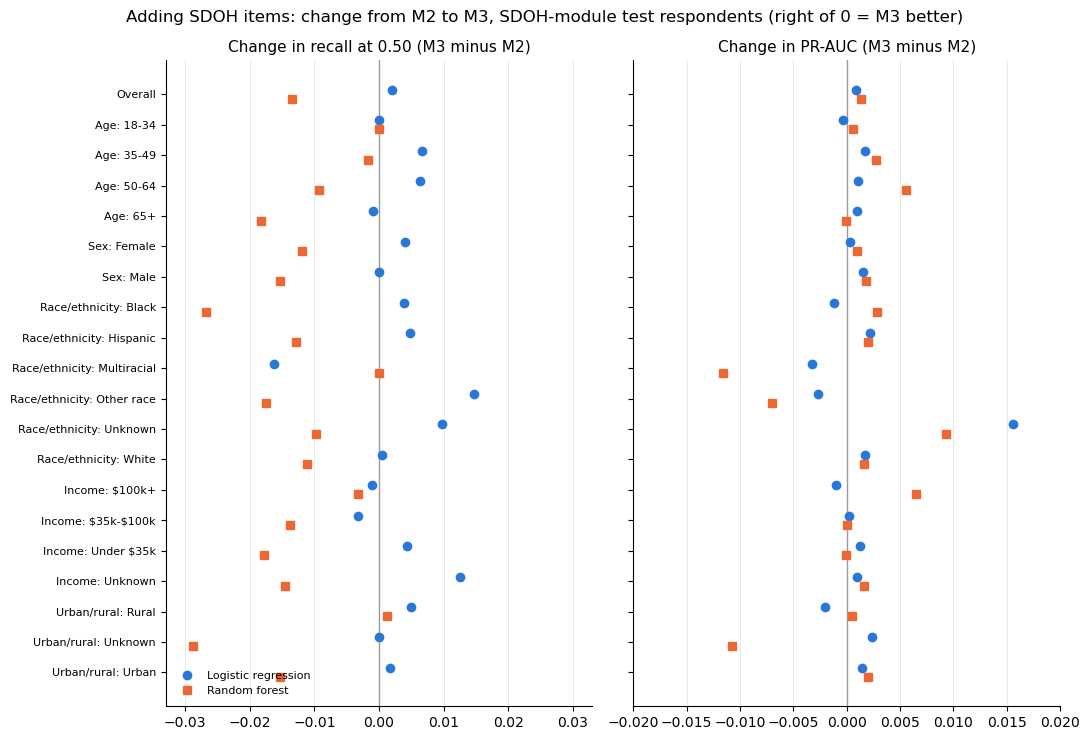

In [27]:
# Step 8 figure: change from adding SDOH items (M3 minus M2) in recall at 0.50 and in PR-AUC, overall and by subgroup
ov = diff8[diff8["cutoff"] == CUTOFF][["kind", "recall (M3-M2)", "PR-AUC (M3-M2)"]].rename(
    columns={"recall (M3-M2)": "recall M3-M2", "PR-AUC (M3-M2)": "PR-AUC M3-M2"}).assign(label="Overall")
s = side[side["cutoff"] == CUTOFF].copy()
s["label"] = (s["grouping"].map(GROUP_TITLES) + ": " + s["group"].astype(str)).str.replace("$", r"\$", regex=False)
plot8 = pd.concat([ov, s[["kind", "label", "recall M3-M2", "PR-AUC M3-M2"]]], ignore_index=True)
labels = list(dict.fromkeys(plot8["label"]))[::-1]
ypos = {l: i for i, l in enumerate(labels)}
MK8 = {"logreg": ("#2a78d6", "o", "Logistic regression"), "rf": ("#eb6834", "s", "Random forest")}
fig, axes = plt.subplots(1, 2, figsize=(11, 7.5), sharey=True)
for ax, col, title in zip(axes, ["recall M3-M2", "PR-AUC M3-M2"], ["Change in recall at 0.50", "Change in PR-AUC"]):
    ax.axvline(0, color="#9a9a96", lw=1)
    for kind, (c, mk, lab) in MK8.items():
        d = plot8[plot8["kind"] == kind]
        off = 0.15 if mk == "o" else -0.15
        ax.plot(d[col], [ypos[l] + off for l in d["label"]], mk, color=c, ms=6, ls="none", label=lab)
    lim = max(0.02, plot8[col].abs().max() * 1.15)
    ax.set_xlim(-lim, lim)
    ax.set_title(title + " (M3 minus M2)", fontsize=11)
    ax.grid(axis="x", color="#e6e5e0", lw=0.6); ax.spines[["top", "right"]].set_visible(False)
axes[0].set_yticks(range(len(labels)), labels, fontsize=8)
axes[0].legend(frameon=False, fontsize=8, loc="lower left")
fig.suptitle("Adding SDOH items: change from M2 to M3, SDOH-module test respondents (right of 0 = M3 better)", fontsize=12)
fig.tight_layout()
fig.savefig(os.path.join(OUTPUTS, "fig_step8_M3_minus_M2_test.png"), dpi=200)
plot8.to_csv(os.path.join(OUTPUTS, "fig_step8_M3_minus_M2_test.csv"), index=False)
plt.show()

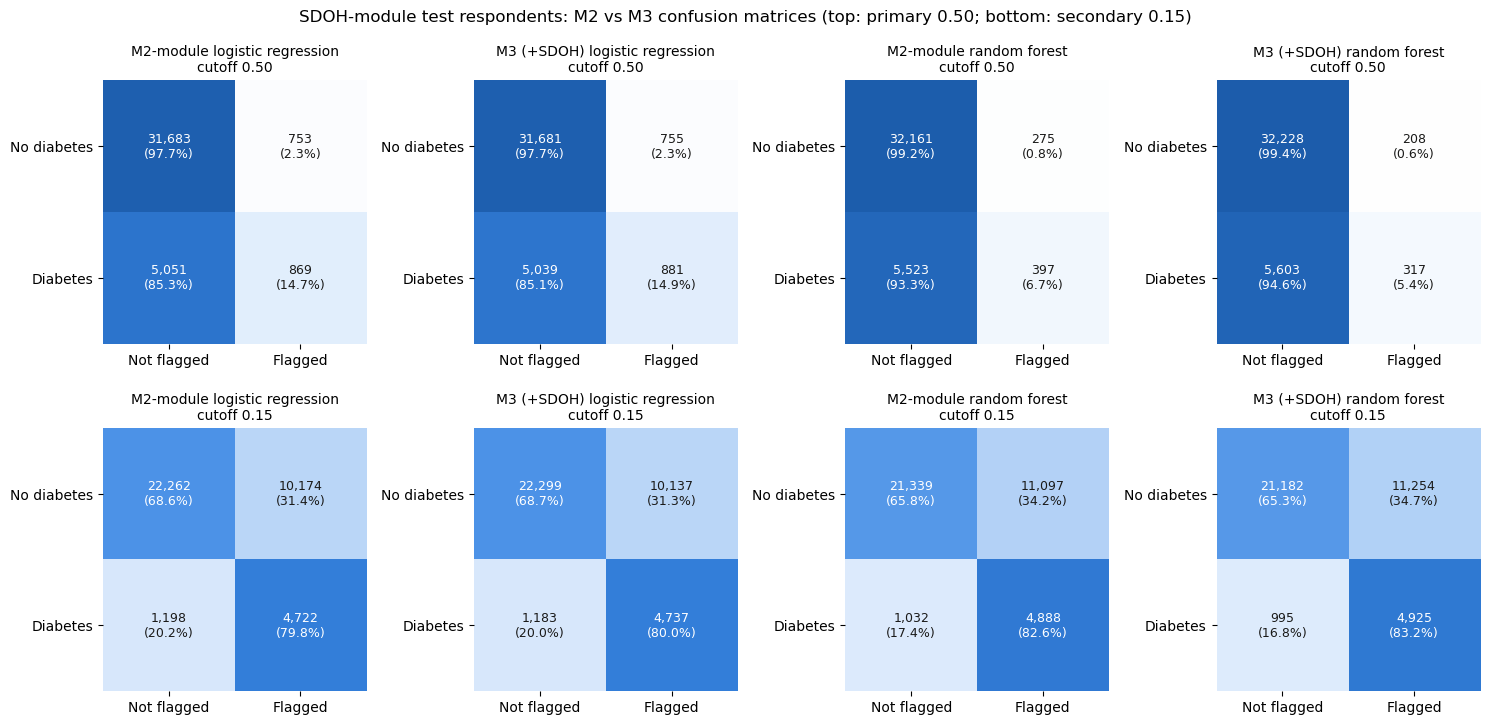

In [28]:
# Step 8: confusion matrices, M2-module vs M3 (SDOH-module test respondents), at 0.50 (top) and 0.15 (bottom)
# Drawn from the step 8 results already computed above; no re-scoring.
order8 = [("M2", "logreg"), ("M3", "logreg"), ("M2", "rf"), ("M3", "rf")]
fig, axes = plt.subplots(2, 4, figsize=(15, 7.4))
cm8_rows = []
for row_i, cut in enumerate([CUTOFF, 0.15]):
    for col_i, (m, kind) in enumerate(order8):
        ax = axes[row_i, col_i]
        r = res8[(res8["model"] == m) & (res8["kind"] == kind) & (res8["cutoff"] == cut)].iloc[0]
        cm = np.array([[r["cleared"], r["false_alarms"]], [r["missed"], r["caught"]]])
        row_pct = cm / cm.sum(axis=1, keepdims=True)
        ax.imshow(row_pct, cmap=BLUES, vmin=0, vmax=1)
        for i in range(2):
            for j in range(2):
                ax.text(j, i, f"{int(cm[i, j]):,}\n({100 * row_pct[i, j]:.1f}%)", ha="center", va="center", fontsize=9,
                        color="white" if row_pct[i, j] > 0.6 else "#1a1a19")
        ax.set_xticks([0, 1], ["Not flagged", "Flagged"]); ax.set_yticks([0, 1], ["No diabetes", "Diabetes"])
        name = ("M2-module" if m == "M2" else "M3 (+SDOH)") + f" {LABEL[kind]}"
        ax.set_title(f"{name}\ncutoff {cut:.2f}", fontsize=10)
        for s_ in ax.spines.values(): s_.set_visible(False)
        cm8_rows.append({"model": m, "kind": kind, "cutoff": cut, "TN_cleared": int(r["cleared"]),
                         "FP_false_alarms": int(r["false_alarms"]), "FN_missed": int(r["missed"]), "TP_caught": int(r["caught"])})
fig.suptitle("SDOH-module test respondents: M2 vs M3 confusion matrices (top: primary 0.50; bottom: secondary 0.15)", fontsize=12)
fig.tight_layout()
fig.savefig(os.path.join(OUTPUTS, "fig_step8_confusion_matrices_M2_vs_M3_test.png"), dpi=200)
pd.DataFrame(cm8_rows).to_csv(os.path.join(OUTPUTS, "fig_step8_confusion_matrices_M2_vs_M3_test.csv"), index=False)
plt.show()

## Step 10a: what drives M2? Permutation importance on VALIDATION rows (decision F10a)
For each of M2's 17 survey features, we shuffle that one column across validation respondents (breaking its link to diabetes)
and measure how much ROC-AUC drops. A big drop means the model relies on that answer to rank people.
Done for the final full-sample M2 logistic regression and M2 random forest (step 6 models, no refitting), 5 repeats each.
Validation rows only: the test set is not used. Correlated features can share importance; importance is not causation or direction.

**In the report:** discussion text and an appendix candidate (`fig_step10_permutation_importance_M2_validation.png`).

Loaded cached permutation importance from outputs/step10_permutation_importance_M2_validation.csv


model,M2 logistic regression,M2 random forest
label,,
Age group,0.1124,0.0718
General health,0.0607,0.0523
BMI,0.0305,0.0326
Time since checkup,0.0197,0.0207
Drinking days per 30,0.0115,0.0129
Race/ethnicity,0.0073,0.0051
Sex,0.0065,0.0064
Personal doctor,0.0061,0.0064
Any exercise (30 days),0.0018,0.0038


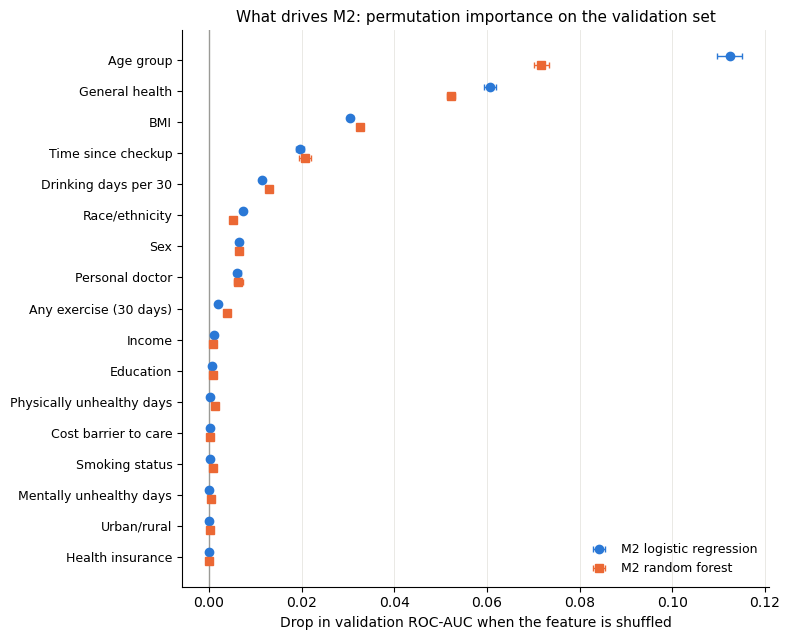

In [29]:
# Step 10a: permutation importance (F10a), cached
from sklearn.inspection import permutation_importance
N_REPEATS = 5
PI_FILE = os.path.join(OUTPUTS, "step10_permutation_importance_M2_validation.csv")
NICE = {"_AGEG5YR": "Age group", "SEXVAR": "Sex", "_RACEGR3": "Race/ethnicity", "_EDUCAG": "Education",
        "_INCOMG1": "Income", "_URBSTAT": "Urban/rural", "BMI": "BMI", "_SMOKER3": "Smoking status",
        "EXERANY2": "Any exercise (30 days)", "ALC_DAYS30": "Drinking days per 30", "_HLTHPL2": "Health insurance",
        "PERSDOC3": "Personal doctor", "MEDCOST1": "Cost barrier to care", "CHECKUP1": "Time since checkup",
        "GENHLTH": "General health", "PHYSHLTH": "Physically unhealthy days", "MENTHLTH": "Mentally unhealthy days"}
if os.path.exists(PI_FILE):
    pi = pd.read_csv(PI_FILE)
    print("Loaded cached permutation importance from", PI_FILE)
else:
    val = get_part(data, "val")
    feats = MODELS["M2"]
    rows = []
    for kind in ["logreg", "rf"]:
        t0 = time.time()
        r = permutation_importance(final[("M2", kind)]["pipe"], val[feats], val["target"], scoring="roc_auc",
                                   n_repeats=N_REPEATS, random_state=SEED, n_jobs=-1 if kind == "logreg" else 1)
        for j, f in enumerate(feats):
            rows.append({"model": f"M2 {LABEL[kind]}", "feature": f, "label": NICE[f],
                         "mean_ROC_AUC_drop": r.importances_mean[j], "sd_ROC_AUC_drop": r.importances_std[j],
                         **{f"repeat{k+1}": v for k, v in enumerate(r.importances[j])}})
        print(f"M2 {LABEL[kind]}: {time.time() - t0:.0f}s")
    pi = pd.DataFrame(rows)
    pi["rank"] = pi.groupby("model")["mean_ROC_AUC_drop"].rank(ascending=False).astype(int)
    pi.to_csv(PI_FILE, index=False)
display(pi.pivot(index="label", columns="model", values="mean_ROC_AUC_drop")
          .sort_values("M2 logistic regression", ascending=False).round(4))

# Figure: mean drop in ROC-AUC (with SD over repeats), features ordered by the logistic regression ranking
order_f = (pi[pi["model"] == "M2 logistic regression"].sort_values("mean_ROC_AUC_drop")["label"].tolist())
ypos = {l: i for i, l in enumerate(order_f)}
MKP = {"M2 logistic regression": ("#2a78d6", "o"), "M2 random forest": ("#eb6834", "s")}
fig, ax = plt.subplots(figsize=(8, 6.5))
for name, (c, mk) in MKP.items():
    d = pi[pi["model"] == name]
    off = 0.15 if mk == "o" else -0.15
    ax.errorbar(d["mean_ROC_AUC_drop"], [ypos[l] + off for l in d["label"]], xerr=d["sd_ROC_AUC_drop"],
                fmt=mk, color=c, ms=6, capsize=2, lw=1, label=name)
ax.axvline(0, color="#9a9a96", lw=1)
ax.set_yticks(range(len(order_f)), order_f, fontsize=9)
ax.set_xlabel("Drop in validation ROC-AUC when the feature is shuffled")
ax.grid(axis="x", color="#e6e5e0", lw=0.6); ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=9, loc="lower right")
ax.set_title("What drives M2: permutation importance on the validation set", fontsize=11)
fig.tight_layout()
fig.savefig(os.path.join(OUTPUTS, "fig_step10_permutation_importance_M2_validation.png"), dpi=200)
plt.show()

## Step 10b: report tables and main figures (decisions R7b, R7c, FIG1–FIG4)
- **Cutoffs (R7b):** 0.15 leads, 0.50 is reported alongside everywhere. 0.50 was set first; 0.15 (= training diabetes rate, to account
  for class imbalance) was added after seeing that 0.50 flagged few people. Disclosed.
- **Threshold table (R7c):** M2 logistic regression at fixed cutoffs 0.10, 0.15, 0.20, 0.30, 0.50 (appendix).
- **Main figures:** (1) confusion matrices for M0–M2 logistic regression at 0.15 and 0.50; (2) subgroup recall and precision for
  M2 logistic regression at both cutoffs (FIG1, FIG2); (3) M2-module vs M3 logistic regression at 0.15 (FIG3).
- **Tables (FIG4):** Table 1 = recall, precision, F1, ROC-AUC for every M0–M2 model at both cutoffs; Table 2 = the same for M2-module vs M3.

Everything here is computed from the test predictions saved in steps 7 and 8. Nothing is refit and the test file is not re-read.

**Later update (FIG1b):** main Figure 2 shows **0.15 only**, with values printed next to each dot. The both-cutoffs version is the appendix figure `fig_appx_subgroup_recall_precision_M2_logistic_test_both_cutoffs.png`.
Cells below, in order: threshold table (appendix), Tables 1–2 (main), Figure 1 (main), appendix subgroup figure, Figure 2 (main), Figure 3 (main).

In [30]:
# Step 10b (R7c): threshold table for M2 logistic regression at fixed cutoffs (appendix)
import datetime
THRESHOLDS = [0.10, 0.15, 0.20, 0.30, 0.50]          # fixed before computing (R7c)
REC_C = os.path.join(OUTPUTS, "step10_threshold_table_record.csv")
if not os.path.exists(REC_C):
    pd.DataFrame([{"computed_on": datetime.datetime.now().isoformat(timespec="seconds"),
                   "note": "R7c threshold table on saved step 7 test predictions (additional look, disclosed)"}]).to_csv(REC_C, index=False)
r = test_res[("M2", "logreg")]
thr_tab = pd.DataFrame([{"cutoff": c, **score(r["part"]["target"], r["p"], c)} for c in THRESHOLDS])
thr_tab.to_csv(os.path.join(OUTPUTS, "step10_threshold_table_M2_logistic_test.csv"), index=False)
display(thr_tab[["cutoff", "recall", "precision", "F1", "false_pos_rate", "flagged_%", "caught", "missed", "false_alarms"]].round(3))

,cutoff,recall,precision,F1,false_pos_rate,flagged_%,caught,missed,false_alarms
0,0.10,0.893,0.268,0.413,0.428,49.707,11574,1390,31568
1,0.15,0.789,0.315,0.450,0.302,37.453,10235,2729,22272
2,0.20,0.681,0.359,0.470,0.214,28.343,8823,4141,15777
3,0.30,0.451,0.429,0.440,0.106,15.719,5848,7116,7795
4,0.50,0.147,0.540,0.231,0.022,4.071,1908,11056,1625


In [31]:
# Step 10b (FIG4): Table 1 (M0–M2) and Table 2 (M2-module vs M3): recall, precision, F1 at 0.15 and 0.50, plus ROC-AUC
MAIN_CUT, SECOND_CUT = 0.15, 0.50
def fmt3(x):
    return "undefined" if pd.isna(x) else f"{x:.3f}"

def metrics_row(name, y, p):
    a, b = score(y, p, MAIN_CUT), score(y, p, SECOND_CUT)
    return {"model": name,
            "recall @0.15": a["recall"], "precision @0.15": a["precision"], "F1 @0.15": a["F1"],
            "recall @0.50": b["recall"], "precision @0.50": b["precision"], "F1 @0.50": b["F1"],
            "ROC-AUC": a["ROC-AUC"], "n": a["n"], "positives": a["positives"]}

table1 = pd.DataFrame([metrics_row(f"{m} {LABEL[k]}", test_res[(m, k)]["part"]["target"], test_res[(m, k)]["p"]) for m, k in order])
table1.to_csv(os.path.join(OUTPUTS, "table1_test_metrics_M0_M2.csv"), index=False)
table2 = pd.DataFrame([metrics_row(("M2-module" if m == "M2" else "M3 (+SDOH)") + f" {LABEL[k]}",
                                   test_res8[(m, k)]["part"]["target"], test_res8[(m, k)]["p"])
                       for m, k in [("M2", "logreg"), ("M3", "logreg"), ("M2", "rf"), ("M3", "rf")]])
table2.to_csv(os.path.join(OUTPUTS, "table2_test_metrics_M2_vs_M3_module.csv"), index=False)
show_t = ["model", "recall @0.15", "precision @0.15", "F1 @0.15", "recall @0.50", "precision @0.50", "F1 @0.50", "ROC-AUC"]
print("Table 1: test set, all respondents (n = 86,793)")
display(table1[show_t].map(lambda x: fmt3(x) if isinstance(x, float) else x))
print("Table 2: test set, SDOH-module respondents (n = 38,356)")
display(table2[show_t].map(lambda x: fmt3(x) if isinstance(x, float) else x))

Table 1: test set, all respondents (n = 86,793)


,model,recall @0.15,precision @0.15,F1 @0.15,recall @0.50,precision @0.50,F1 @0.50,ROC-AUC
0,M0 logistic regression,0.834,0.212,0.339,0.000,undefined,undefined,0.688
1,M1 logistic regression,0.793,0.235,0.363,0.004,0.490,0.007,0.733
2,M2 logistic regression,0.789,0.315,0.450,0.147,0.540,0.231,0.817
3,M1 random forest,0.798,0.239,0.367,0.000,undefined,undefined,0.738
4,M2 random forest,0.818,0.306,0.446,0.070,0.588,0.125,0.820


Table 2: test set, SDOH-module respondents (n = 38,356)


,model,recall @0.15,precision @0.15,F1 @0.15,recall @0.50,precision @0.50,F1 @0.50,ROC-AUC
0,M2-module logistic regression,0.798,0.317,0.454,0.147,0.536,0.230,0.815
1,M3 (+SDOH) logistic regression,0.800,0.318,0.456,0.149,0.539,0.233,0.814
2,M2-module random forest,0.826,0.306,0.446,0.067,0.591,0.120,0.816
3,M3 (+SDOH) random forest,0.832,0.304,0.446,0.054,0.604,0.098,0.816


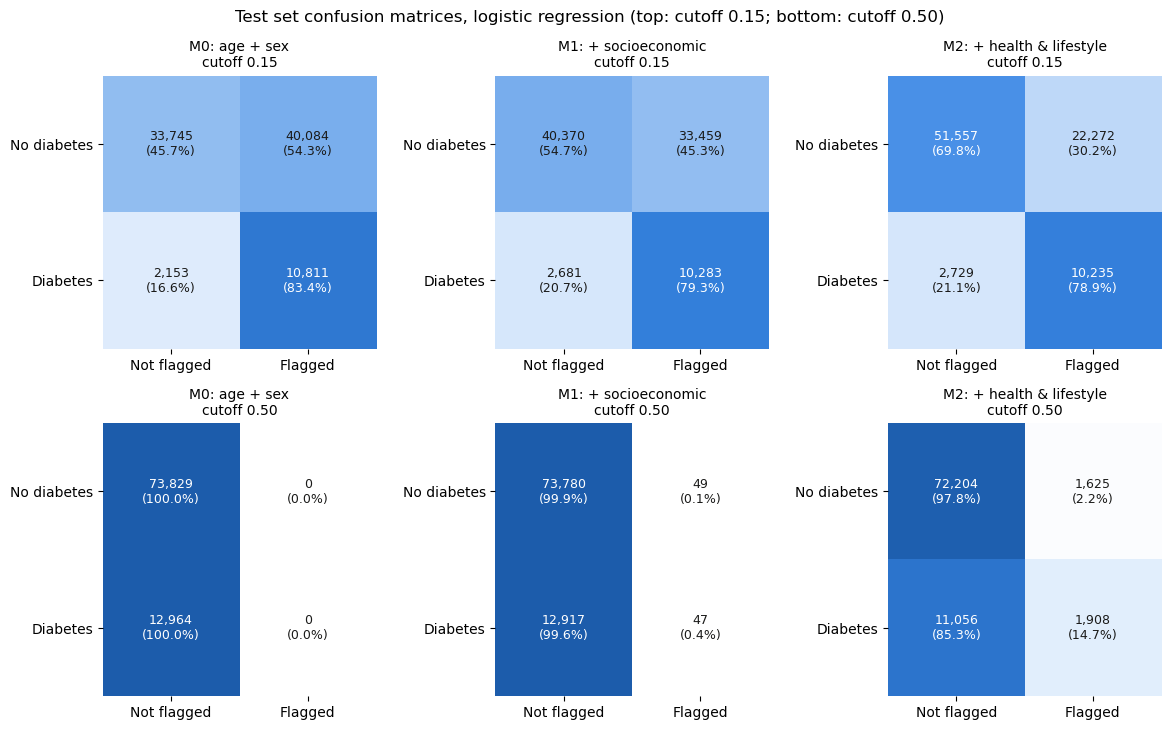

In [32]:
# Step 10b main figure 1: confusion matrices, M0–M2 logistic regression, at 0.15 (top, main) and 0.50 (bottom)
def draw_cm(ax, row, title):
    cm = np.array([[row["cleared"], row["false_alarms"]], [row["missed"], row["caught"]]])
    row_pct = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(row_pct, cmap=BLUES, vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{int(cm[i, j]):,}\n({100 * row_pct[i, j]:.1f}%)", ha="center", va="center", fontsize=9,
                    color="white" if row_pct[i, j] > 0.6 else "#1a1a19")
    ax.set_xticks([0, 1], ["Not flagged", "Flagged"]); ax.set_yticks([0, 1], ["No diabetes", "Diabetes"])
    ax.set_title(title, fontsize=10)
    for s_ in ax.spines.values(): s_.set_visible(False)
    return {"TN_cleared": int(cm[0, 0]), "FP_false_alarms": int(cm[0, 1]), "FN_missed": int(cm[1, 0]), "TP_caught": int(cm[1, 1])}

fig, axes = plt.subplots(2, 3, figsize=(12, 7.4))
rows_cm = []
for ri, cut in enumerate([MAIN_CUT, SECOND_CUT]):
    for ci, m in enumerate(["M0", "M1", "M2"]):
        r = test_res[(m, "logreg")]
        row = score(r["part"]["target"], r["p"], cut)
        sub_t = {"M0": "M0: age + sex", "M1": "M1: + socioeconomic", "M2": "M2: + health & lifestyle"}[m]
        rows_cm.append({"model": f"{m} logistic regression", "cutoff": cut,
                        **draw_cm(axes[ri, ci], row, f"{sub_t}\ncutoff {cut:.2f}")})
fig.suptitle("Test set confusion matrices, logistic regression (top: cutoff 0.15; bottom: cutoff 0.50)", fontsize=12)
fig.tight_layout()
fig.savefig(os.path.join(OUTPUTS, "fig_main1_confusion_matrices_logistic_test.png"), dpi=200)
pd.DataFrame(rows_cm).to_csv(os.path.join(OUTPUTS, "fig_main1_confusion_matrices_logistic_test.csv"), index=False)
plt.show()

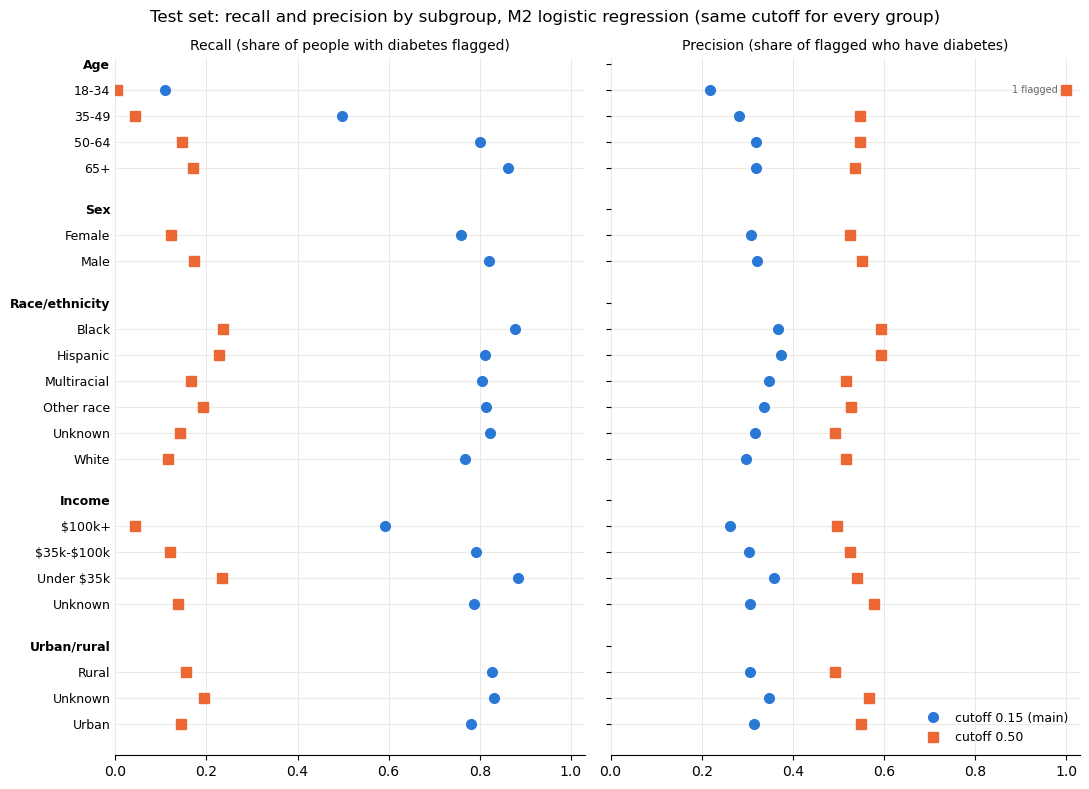

In [33]:
# Step 10b APPENDIX figure: subgroup recall and precision, M2 logistic regression, at 0.15 and 0.50 (FIG1b: moved from main)
name = "M2 logistic regression"
gg = pd.concat([groups_015[groups_015["model"] == name].assign(cut=MAIN_CUT),
                groups_test[groups_test["model"] == name].assign(cut=SECOND_CUT)], ignore_index=True)
gg["n_flagged"] = gg["caught"] + gg["false_alarms"]

# y layout: a bold header row for each grouping, then its groups, then a gap
ticks, tick_labels, header_ticks, ypos, y = [], [], [], {}, 0
for g, title in GROUP_TITLES.items():
    ticks.append(y); tick_labels.append(title); header_ticks.append(y); y += 1
    for lev in gg[gg["grouping"] == g]["group"].drop_duplicates():
        ypos[(g, lev)] = y
        ticks.append(y); tick_labels.append(str(lev).replace("$", r"\$")); y += 1
    y += 0.6

STY = {MAIN_CUT: dict(color="#2a78d6", marker="o", label="cutoff 0.15 (main)"),
       SECOND_CUT: dict(color="#eb6834", marker="s", label="cutoff 0.50")}
fig, axes = plt.subplots(1, 2, figsize=(11, 8), sharey=True)
for ax, metric, title in zip(axes, ["recall", "precision"], ["Recall (share of people with diabetes flagged)",
                                                             "Precision (share of flagged who have diabetes)"]):
    for (g, lev), yy in ypos.items():
        ax.axhline(yy, color="#ecebe6", lw=0.8, zorder=0)
    for cut, st in STY.items():
        d = gg[gg["cut"] == cut]
        ax.plot(d[metric], [ypos[(g, l)] for g, l in zip(d["grouping"], d["group"])], st["marker"], color=st["color"],
                ms=7, ls="none", label=st["label"], zorder=3)
        if metric == "precision":   # flag precision values based on very few flagged people
            for _, rr in d[d["n_flagged"] < 20].iterrows():
                ax.annotate(f"{int(rr['n_flagged'])} flagged", (rr[metric], ypos[(rr['grouping'], rr['group'])]),
                            xytext=(-6, 0), textcoords="offset points", ha="right", va="center", fontsize=7, color="#6b6a65")
    ax.set_xlim(0, 1.03)               # a little room so markers at 1.0 are not cut off
    ax.set_title(title, fontsize=10)
    ax.grid(axis="x", color="#e6e5e0", lw=0.6); ax.spines[["top", "right", "left"]].set_visible(False)
axes[0].set_yticks(ticks, tick_labels, fontsize=9)
for t, lab in zip(axes[0].get_yticklabels(), tick_labels):
    if ticks[tick_labels.index(lab)] in header_ticks and lab in GROUP_TITLES.values():
        t.set_fontweight("bold")
axes[0].tick_params(axis="y", length=0)
axes[0].invert_yaxis()
axes[1].legend(frameon=False, fontsize=9, loc="lower right")
fig.suptitle("Test set: recall and precision by subgroup, M2 logistic regression (same cutoff for every group)", fontsize=12)
fig.tight_layout()
fig.savefig(os.path.join(OUTPUTS, "fig_appx_subgroup_recall_precision_M2_logistic_test_both_cutoffs.png"), dpi=200)
gg[["cut", "grouping", "group", "n", "positives", "prevalence", "recall", "precision", "false_pos_rate", "n_flagged"]].to_csv(
    os.path.join(OUTPUTS, "fig_appx_subgroup_recall_precision_M2_logistic_test_both_cutoffs.csv"), index=False)
plt.show()

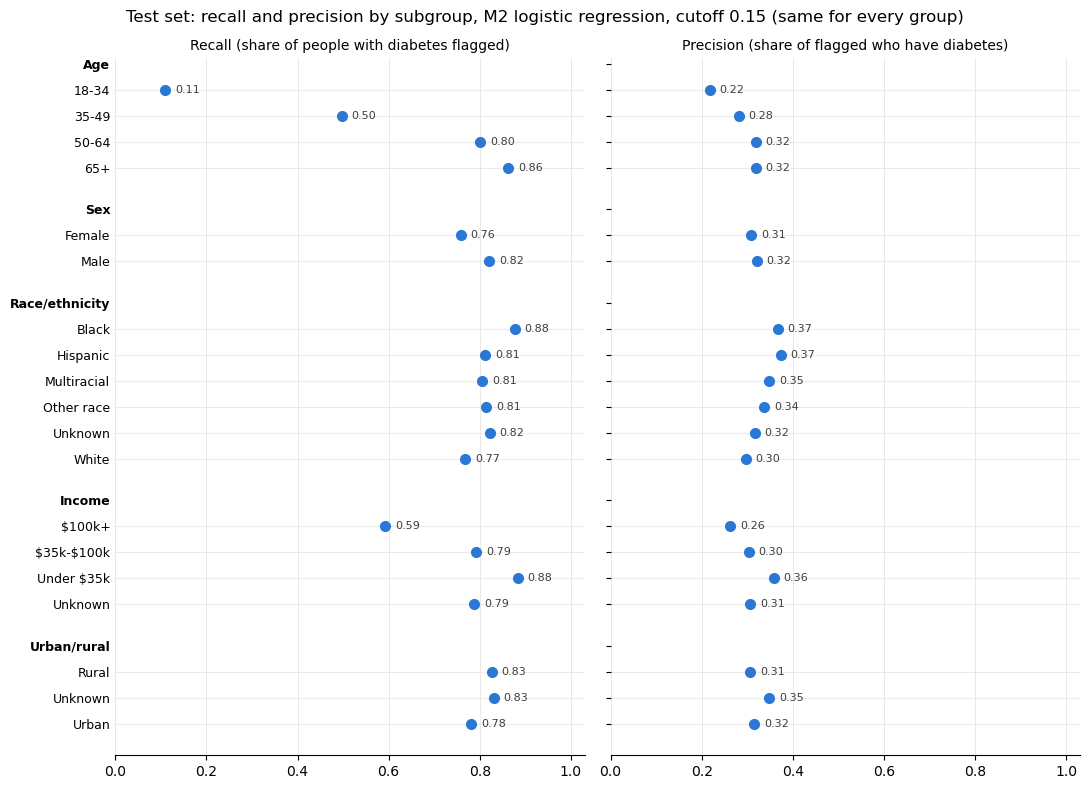

In [34]:
# Step 10b MAIN figure 2 (FIG1b): subgroup recall and precision, M2 logistic regression, cutoff 0.15 only, values labelled
g15 = gg[gg["cut"] == MAIN_CUT]
fig, axes = plt.subplots(1, 2, figsize=(11, 8), sharey=True)
for ax, metric, title in zip(axes, ["recall", "precision"], ["Recall (share of people with diabetes flagged)",
                                                             "Precision (share of flagged who have diabetes)"]):
    for yy in ypos.values():
        ax.axhline(yy, color="#ecebe6", lw=0.8, zorder=0)
    ys = [ypos[(g, l)] for g, l in zip(g15["grouping"], g15["group"])]
    ax.plot(g15[metric], ys, "o", color="#2a78d6", ms=7, ls="none", zorder=3)
    for v, yy in zip(g15[metric], ys):
        ax.annotate(f"{v:.2f}", (v, yy), xytext=(7, 0), textcoords="offset points", va="center", fontsize=8, color="#3d3d3a")
    ax.set_xlim(0, 1.03)          # same 0-1 scale on both panels, so similar precision values look similar
    ax.set_title(title, fontsize=10)
    ax.grid(axis="x", color="#e6e5e0", lw=0.6); ax.spines[["top", "right", "left"]].set_visible(False)
axes[0].set_yticks(ticks, tick_labels, fontsize=9)
for t, tk in zip(axes[0].get_yticklabels(), ticks):
    if tk in header_ticks:
        t.set_fontweight("bold")
axes[0].tick_params(axis="y", length=0)
axes[0].invert_yaxis()
fig.suptitle("Test set: recall and precision by subgroup, M2 logistic regression, cutoff 0.15 (same for every group)", fontsize=12)
fig.tight_layout()
fig.savefig(os.path.join(OUTPUTS, "fig_main2_subgroup_recall_precision_M2_logistic_test.png"), dpi=200)
g15[["grouping", "group", "n", "positives", "prevalence", "recall", "precision", "false_pos_rate", "n_flagged"]].to_csv(
    os.path.join(OUTPUTS, "fig_main2_subgroup_recall_precision_M2_logistic_test.csv"), index=False)
plt.show()

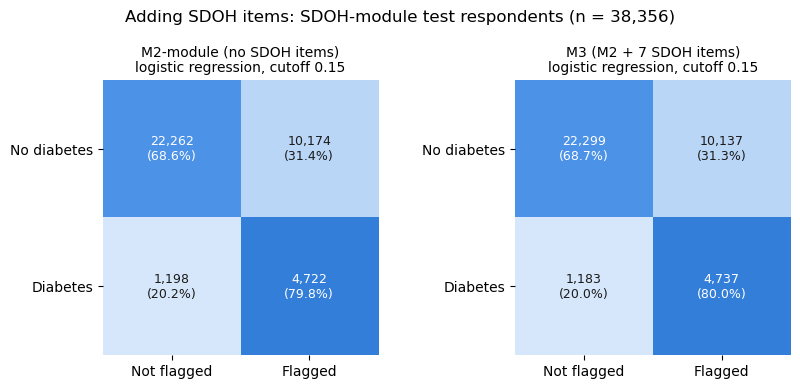

In [35]:
# Step 10b main figure 3: M2-module vs M3 logistic regression at the main cutoff 0.15 (SDOH-module test respondents)
fig, axes = plt.subplots(1, 2, figsize=(8.4, 3.9))
rows_cm3 = []
for ax, m in zip(axes, ["M2", "M3"]):
    r = test_res8[(m, "logreg")]
    row = score(r["part"]["target"], r["p"], MAIN_CUT)
    t = "M2-module (no SDOH items)" if m == "M2" else "M3 (M2 + 7 SDOH items)"
    rows_cm3.append({"model": t, "cutoff": MAIN_CUT, **draw_cm(ax, row, f"{t}\nlogistic regression, cutoff 0.15")})
fig.suptitle("Adding SDOH items: SDOH-module test respondents (n = 38,356)", fontsize=12)
fig.tight_layout()
fig.savefig(os.path.join(OUTPUTS, "fig_main3_confusion_M2_vs_M3_logistic_015_test.png"), dpi=200)
pd.DataFrame(rows_cm3).to_csv(os.path.join(OUTPUTS, "fig_main3_confusion_M2_vs_M3_logistic_015_test.csv"), index=False)
plt.show()

## End of analysis notebook
Step 8 is complete above. Step 9 (full threshold sensitivity) was dropped (R7; one secondary cutoff added, R7a). Step 10 (diagnostics and write-up) follows.

**Later update:** step 10 is complete. Step 10a (permutation importance) and step 10b (report tables and main figures) are above; the write-up is in the report.